In [112]:

# PHASE 1 : IMPORT LIBRARIES & LOAD DATASET


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("upi_spending_analysis_11620_records.csv")

df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Hostel_or_DayScholar,Monthly_Allowance,Monthly_UPI_Spending,Food_Spending,Shopping_Spending,...,Savings,Daily_UPI_Transactions,Preferred_UPI_App,Part_Time_Job,Monthly_Extra_Income,Tracks_Budget,Cashback_Influence (1-5),Impulse_Buying_Score (1-5),Financial_Stress (1-5),Satisfaction_with_UPI (1-5)
0,STU000001,23,Female,3,Civil,Day Scholar,9401,5170,2080,883,...,3845,3,Paytm,No,0,Yes,3,3,4,5
1,STU000002,23,Female,2,Civil,Day Scholar,13281,10467,5742,1068,...,5232,6,Paytm,Yes,3031,No,3,4,3,4
2,STU000003,22,Female,1,AI-ML,Hostel,7322,9445,4034,846,...,1839,3,Paytm,Yes,4364,No,3,3,3,4
3,STU000004,18,Male,3,CSE,Hostel,8344,5699,1254,476,...,1856,4,PhonePe,No,0,No,4,2,3,3
4,STU000005,21,Female,1,EEE,Hostel,32116,15136,6678,1711,...,17601,2,PhonePe,No,0,No,3,3,4,5


In [113]:

# PHASE 2 : DATASET INFORMATION

print("Shape of Dataset :", df.shape)

print("\nColumn Names")
print(df.columns)

print("\nData Types")
print(df.dtypes)

print("\nDataset Information")
df.info()

Shape of Dataset : (11620, 24)

Column Names
Index(['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Department',
       'Hostel_or_DayScholar', 'Monthly_Allowance', 'Monthly_UPI_Spending',
       'Food_Spending', 'Shopping_Spending', 'Travel_Spending',
       'Entertainment_Spending', 'Education_Spending', 'Recharge_Bills',
       'Savings', 'Daily_UPI_Transactions', 'Preferred_UPI_App',
       'Part_Time_Job', 'Monthly_Extra_Income', 'Tracks_Budget',
       'Cashback_Influence (1-5)', 'Impulse_Buying_Score (1-5)',
       'Financial_Stress (1-5)', 'Satisfaction_with_UPI   (1-5)'],
      dtype='str')

Data Types
Student_ID                         str
Age                              int64
Gender                             str
Year_of_Study                    int64
Department                         str
Hostel_or_DayScholar               str
Monthly_Allowance                int64
Monthly_UPI_Spending             int64
Food_Spending                    int64
Shopping_Spending            

In [114]:

# PHASE 3 : CHECK MISSING VALUES


missing = df.isnull().sum()

print("Missing Values in Each Column")
print(missing)

missing_percent = (df.isnull().sum()/len(df))*100

print("\nMissing Percentage")
print(missing_percent)

Missing Values in Each Column
Student_ID                       0
Age                              0
Gender                           0
Year_of_Study                    0
Department                       0
Hostel_or_DayScholar             0
Monthly_Allowance                0
Monthly_UPI_Spending             0
Food_Spending                    0
Shopping_Spending                0
Travel_Spending                  0
Entertainment_Spending           0
Education_Spending               0
Recharge_Bills                   0
Savings                          0
Daily_UPI_Transactions           0
Preferred_UPI_App                0
Part_Time_Job                    0
Monthly_Extra_Income             0
Tracks_Budget                    0
Cashback_Influence (1-5)         0
Impulse_Buying_Score (1-5)       0
Financial_Stress (1-5)           0
Satisfaction_with_UPI   (1-5)    0
dtype: int64

Missing Percentage
Student_ID                       0.0
Age                              0.0
Gender                 

In [115]:

# PHASE 4 : HANDLE MISSING VALUES


num_cols = df.select_dtypes(include=["int64", "float64"]).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())


cat_cols = df.select_dtypes(include=["object", "string"]).columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing Values After Cleaning")
print(df.isnull().sum())

Missing Values After Cleaning
Student_ID                       0
Age                              0
Gender                           0
Year_of_Study                    0
Department                       0
Hostel_or_DayScholar             0
Monthly_Allowance                0
Monthly_UPI_Spending             0
Food_Spending                    0
Shopping_Spending                0
Travel_Spending                  0
Entertainment_Spending           0
Education_Spending               0
Recharge_Bills                   0
Savings                          0
Daily_UPI_Transactions           0
Preferred_UPI_App                0
Part_Time_Job                    0
Monthly_Extra_Income             0
Tracks_Budget                    0
Cashback_Influence (1-5)         0
Impulse_Buying_Score (1-5)       0
Financial_Stress (1-5)           0
Satisfaction_with_UPI   (1-5)    0
dtype: int64


In [116]:
# ==============================
# PHASE 5 : REMOVE DUPLICATES
# ==============================

print("Duplicate Records Before :", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate Records After :", df.duplicated().sum())

print("New Shape :", df.shape)

Duplicate Records Before : 0
Duplicate Records After : 0
New Shape : (11620, 24)


In [117]:

# PHASE 6 : CLEAN CATEGORICAL VALUES


cat_cols = df.select_dtypes(include=["object", "string"]).columns

for col in cat_cols:
    df[col] = df[col].str.strip()
    df[col] = df[col].str.title()

print(df[cat_cols].head())

  Student_ID  Gender Department Hostel_or_DayScholar Preferred_UPI_App  \
0  Stu000001  Female      Civil          Day Scholar             Paytm   
1  Stu000002  Female      Civil          Day Scholar             Paytm   
2  Stu000003  Female      Ai-Ml               Hostel             Paytm   
3  Stu000004    Male        Cse               Hostel           Phonepe   
4  Stu000005  Female        Eee               Hostel           Phonepe   

  Part_Time_Job Tracks_Budget  
0            No           Yes  
1           Yes            No  
2           Yes            No  
3            No            No  
4            No            No  


In [118]:

# PHASE 7 : CHANGE DATA TYPES


category_columns = [
    "Gender",
    "Year_of_Study",
    "Department",
    "Preferred_UPI_App",
    "Hosteller_or_DayScholar",
    "Tracks_Budget",
    "Part_Time_Job"
]

for col in category_columns:
    if col in df.columns:
        df[col] = df[col].astype("category")

print(df.dtypes)

Student_ID                            str
Age                                 int64
Gender                           category
Year_of_Study                    category
Department                       category
Hostel_or_DayScholar                  str
Monthly_Allowance                   int64
Monthly_UPI_Spending                int64
Food_Spending                       int64
Shopping_Spending                   int64
Travel_Spending                     int64
Entertainment_Spending              int64
Education_Spending                  int64
Recharge_Bills                      int64
Savings                             int64
Daily_UPI_Transactions              int64
Preferred_UPI_App                category
Part_Time_Job                    category
Monthly_Extra_Income                int64
Tracks_Budget                    category
Cashback_Influence (1-5)            int64
Impulse_Buying_Score (1-5)          int64
Financial_Stress (1-5)              int64
Satisfaction_with_UPI   (1-5)     

In [119]:

# PHASE 8 : UNIQUE VALUES


for col in cat_cols:
    print("\n", col)
    print(df[col].value_counts())


 Student_ID
Student_ID
Stu000001    1
Stu000002    1
Stu000003    1
Stu000004    1
Stu000005    1
            ..
Stu011616    1
Stu011617    1
Stu011618    1
Stu011619    1
Stu011620    1
Name: count, Length: 11620, dtype: int64

 Gender
Gender
Male      5946
Female    5418
Other      256
Name: count, dtype: int64

 Department
Department
Cse              2490
Ece              1687
Ai-Ml            1659
It               1501
Mechanical        907
Eee               841
Civil             698
Bba               681
Biotechnology     590
Chemical          566
Name: count, dtype: int64

 Hostel_or_DayScholar
Hostel_or_DayScholar
Hostel         6796
Day Scholar    4824
Name: count, dtype: int64

 Preferred_UPI_App
Preferred_UPI_App
Phonepe       4657
Google Pay    3594
Paytm         1842
Amazon Pay    1169
Bhim           358
Name: count, dtype: int64

 Part_Time_Job
Part_Time_Job
No     9536
Yes    2084
Name: count, dtype: int64

 Tracks_Budget
Tracks_Budget
No     6648
Yes    4972
Name: coun

In [120]:

# PHASE 9 : OUTLIER DETECTION


numeric_cols = df.select_dtypes(include=["int64","float64"]).columns

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    outliers = df[(df[col]<lower) | (df[col]>upper)]

    print(col, ":", len(outliers))

Age : 29
Monthly_Allowance : 370
Monthly_UPI_Spending : 338
Food_Spending : 417
Shopping_Spending : 603
Travel_Spending : 630
Entertainment_Spending : 679
Education_Spending : 598
Recharge_Bills : 703
Savings : 421
Daily_UPI_Transactions : 109
Monthly_Extra_Income : 2084
Cashback_Influence (1-5) : 0
Impulse_Buying_Score (1-5) : 0
Financial_Stress (1-5) : 0
Satisfaction_with_UPI   (1-5) : 0


In [121]:

# PHASE 10 : REMOVE OUTLIERS


numeric_cols = df.select_dtypes(include=["int64","float64"]).columns

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    df = df[(df[col]>=lower) & (df[col]<=upper)]

print("Dataset Shape After Removing Outliers")
print(df.shape)

Dataset Shape After Removing Outliers
(6905, 24)


In [122]:

# PHASE 11 : DATA VALIDATION


# Age should be between 18 and 24
df = df[(df["Age"]>=18) & (df["Age"]<=24)]

# Allowance, Spending and Savings should be positive
df = df[df["Monthly_Allowance"]>0]
df = df[df["Monthly_UPI_Spending"]>=0]
df = df[df["Savings"]>=0]

print(df.shape)

(6664, 24)


In [123]:

# PHASE 12 : LABEL ENCODING


from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

encoded_columns = [
    "Gender",
    "Year_of_Study",
    "Department",
    "Preferred_UPI_App",
    "Hosteller_or_DayScholar",
    "Tracks_Budget",
    "Part_Time_Job"
]

for col in encoded_columns:
    if col in df.columns:
        df[col+"_Encoded"] = encoder.fit_transform(df[col])

df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Hostel_or_DayScholar,Monthly_Allowance,Monthly_UPI_Spending,Food_Spending,Shopping_Spending,...,Cashback_Influence (1-5),Impulse_Buying_Score (1-5),Financial_Stress (1-5),Satisfaction_with_UPI (1-5),Gender_Encoded,Year_of_Study_Encoded,Department_Encoded,Preferred_UPI_App_Encoded,Tracks_Budget_Encoded,Part_Time_Job_Encoded
0,Stu000001,23,Female,3,Civil,Day Scholar,9401,5170,2080,883,...,3,3,4,5,0,2,4,3,1,0
3,Stu000004,18,Male,3,Cse,Hostel,8344,5699,1254,476,...,4,2,3,3,1,2,5,4,0,0
9,Stu000010,21,Female,2,Ece,Hostel,20884,9758,6169,1232,...,2,1,3,5,0,1,6,4,1,0
10,Stu000011,20,Male,4,Biotechnology,Hostel,12188,9474,3885,2782,...,4,4,2,5,1,3,2,2,1,0
11,Stu000012,21,Male,3,Bba,Day Scholar,17567,6177,4112,418,...,2,4,4,4,1,2,1,4,0,0


In [124]:

# PHASE 13 : ONE HOT ENCODING


df = pd.get_dummies(
    df,
    columns=["Preferred_UPI_App"],
    drop_first=True
)

df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Hostel_or_DayScholar,Monthly_Allowance,Monthly_UPI_Spending,Food_Spending,Shopping_Spending,...,Gender_Encoded,Year_of_Study_Encoded,Department_Encoded,Preferred_UPI_App_Encoded,Tracks_Budget_Encoded,Part_Time_Job_Encoded,Preferred_UPI_App_Bhim,Preferred_UPI_App_Google Pay,Preferred_UPI_App_Paytm,Preferred_UPI_App_Phonepe
0,Stu000001,23,Female,3,Civil,Day Scholar,9401,5170,2080,883,...,0,2,4,3,1,0,False,False,True,False
3,Stu000004,18,Male,3,Cse,Hostel,8344,5699,1254,476,...,1,2,5,4,0,0,False,False,False,True
9,Stu000010,21,Female,2,Ece,Hostel,20884,9758,6169,1232,...,0,1,6,4,1,0,False,False,False,True
10,Stu000011,20,Male,4,Biotechnology,Hostel,12188,9474,3885,2782,...,1,3,2,2,1,0,False,True,False,False
11,Stu000012,21,Male,3,Bba,Day Scholar,17567,6177,4112,418,...,1,2,1,4,0,0,False,False,False,True


In [125]:
# Savings Percentage

df["Savings_Percentage"] = (df["Savings"] / df["Monthly_Allowance"]) * 100

df["Savings_Percentage"] = df["Savings_Percentage"].round(2)

df[["Savings", "Monthly_Allowance", "Savings_Percentage"]].head()

,Savings,Monthly_Allowance,Savings_Percentage
0,3845,9401,40.90
3,1856,8344,22.24
9,9643,20884,46.17
10,1756,12188,14.41
11,9095,17567,51.77


In [126]:
# Spending Percentage

df["Spending_Percentage"] = (df["Monthly_UPI_Spending"] / df["Monthly_Allowance"]) * 100

df["Spending_Percentage"] = df["Spending_Percentage"].round(2)

df[["Monthly_UPI_Spending", "Monthly_Allowance", "Spending_Percentage"]].head()

,Monthly_UPI_Spending,Monthly_Allowance,Spending_Percentage
0,5170,9401,54.99
3,5699,8344,68.30
9,9758,20884,46.72
10,9474,12188,77.73
11,6177,17567,35.16


In [127]:
# Remaining Balance

df["Remaining_Balance"] = df["Monthly_Allowance"] - df["Monthly_UPI_Spending"]

df[["Monthly_Allowance", "Monthly_UPI_Spending", "Remaining_Balance"]].head()

,Monthly_Allowance,Monthly_UPI_Spending,Remaining_Balance
0,9401,5170,4231
3,8344,5699,2645
9,20884,9758,11126
10,12188,9474,2714
11,17567,6177,11390


In [128]:
# Total Financial Activity

df["Total_Financial_Activity"] = df["Monthly_UPI_Spending"] + df["Savings"]

df[["Monthly_UPI_Spending", "Savings", "Total_Financial_Activity"]].head()

,Monthly_UPI_Spending,Savings,Total_Financial_Activity
0,5170,3845,9015
3,5699,1856,7555
9,9758,9643,19401
10,9474,1756,11230
11,6177,9095,15272


In [129]:
# High Spender

df["High_Spender"] = (df["Spending_Percentage"] > 80).astype(int)

df[["Spending_Percentage", "High_Spender"]].head()

,Spending_Percentage,High_Spender
0,54.99,0
3,68.30,0
9,46.72,0
10,77.73,0
11,35.16,0


In [130]:
# Smart Saver

df["Smart_Saver"] = ((df["Savings_Percentage"] >= 30) & (df["Tracks_Budget"] == "Yes")).astype(int)

df[["Savings_Percentage", "Tracks_Budget", "Smart_Saver"]].head()

,Savings_Percentage,Tracks_Budget,Smart_Saver
0,40.90,Yes,1
3,22.24,No,0
9,46.17,Yes,1
10,14.41,Yes,0
11,51.77,No,0


In [131]:
# Income Category

bins = [0, 5000, 10000, 15000, 25000]
labels = ["Low", "Medium", "High", "Very High"]

df["Income_Category"] = pd.cut(df["Monthly_Allowance"], bins=bins, labels=labels)

df[["Monthly_Allowance", "Income_Category"]].head()

,Monthly_Allowance,Income_Category
0,9401,Medium
3,8344,Medium
9,20884,Very High
10,12188,High
11,17567,Very High


In [132]:
# Spending Category

bins = [0, 2000, 4000, 6000, 10000]
labels = ["Low", "Moderate", "High", "Very High"]

df["Spending_Category"] = pd.cut(df["Monthly_UPI_Spending"], bins=bins, labels=labels)

df[["Monthly_UPI_Spending", "Spending_Category"]].head()

,Monthly_UPI_Spending,Spending_Category
0,5170,High
3,5699,High
9,9758,Very High
10,9474,Very High
11,6177,Very High


In [133]:
# Savings Category

bins = [0, 1000, 3000, 5000, 10000]
labels = ["Poor Saver", "Average Saver", "Good Saver", "Excellent Saver"]

df["Savings_Category"] = pd.cut(df["Savings"], bins=bins, labels=labels)

df[["Savings", "Savings_Category"]].head()

,Savings,Savings_Category
0,3845,Good Saver
3,1856,Average Saver
9,9643,Excellent Saver
10,1756,Average Saver
11,9095,Excellent Saver


In [134]:
# Financial Health Score

df["Financial_Health_Score"] = (df["Savings_Percentage"] + (100 - df["Spending_Percentage"])) / 2

df["Financial_Health_Score"] = df["Financial_Health_Score"].round(2)

df[["Savings_Percentage", "Spending_Percentage", "Financial_Health_Score"]].head()

,Savings_Percentage,Spending_Percentage,Financial_Health_Score
0,40.90,54.99,42.96
3,22.24,68.30,26.97
9,46.17,46.72,49.72
10,14.41,77.73,18.34
11,51.77,35.16,58.31


In [135]:
# Lifestyle Score

df["Lifestyle_Score"] = (
    df["Impulse_Buying_Score (1-5)"] +
    df["Cashback_Influence (1-5)"] +
    df["Financial_Stress (1-5)"]
)

df[[
    "Impulse_Buying_Score (1-5)",
    "Cashback_Influence (1-5)",
    "Financial_Stress (1-5)",
    "Lifestyle_Score"
]].head()

,Impulse_Buying_Score (1-5),Cashback_Influence (1-5),Financial_Stress (1-5),Lifestyle_Score
0,3,3,4,10
3,2,4,3,9
9,1,2,3,6
10,4,4,2,10
11,4,2,4,10


In [136]:
# Savings Efficiency Score

df["Savings_Efficiency"] = df["Savings"] / (df["Monthly_UPI_Spending"] + 1)

df["Savings_Efficiency"] = df["Savings_Efficiency"].round(2)

df[["Savings", "Monthly_UPI_Spending", "Savings_Efficiency"]].head()

,Savings,Monthly_UPI_Spending,Savings_Efficiency
0,3845,5170,0.74
3,1856,5699,0.33
9,9643,9758,0.99
10,1756,9474,0.19
11,9095,6177,1.47


In [137]:
# Cashback Benefit Score

df["Cashback_Benefit_Score"] = (
    df["Cashback_Influence (1-5)"] * df["Monthly_UPI_Spending"]
)

df[[
    "Cashback_Influence (1-5)",
    "Monthly_UPI_Spending",
    "Cashback_Benefit_Score"
]].head()

,Cashback_Influence (1-5),Monthly_UPI_Spending,Cashback_Benefit_Score
0,3,5170,15510
3,4,5699,22796
9,2,9758,19516
10,4,9474,37896
11,2,6177,12354


In [138]:
# Budget Discipline Score
df["Tracks_Budget"] = df["Tracks_Budget"].astype(str).str.strip().str.title()
df["Budget_Status"] = df["Tracks_Budget"].map({"Yes": 10, "No": 0})
df["Budget_Status"] = df["Budget_Status"].fillna(0)
df["Budget_Discipline_Score"] = (
    df["Budget_Status"] + (df["Savings_Percentage"] / 10)
)

df["Budget_Discipline_Score"] = df["Budget_Discipline_Score"].round(2)
df[[
    "Tracks_Budget",
    "Budget_Status",
    "Savings_Percentage",
    "Budget_Discipline_Score"
]].head()

,Tracks_Budget,Budget_Status,Savings_Percentage,Budget_Discipline_Score
0,Yes,10,40.90,14.09
3,No,0,22.24,2.22
9,Yes,10,46.17,14.62
10,Yes,10,14.41,11.44
11,No,0,51.77,5.18


In [139]:
# Impulse Spending Level
df["Impulse_Buying_Score (1-5)"] = df["Impulse_Buying_Score (1-5)"].fillna(
    df["Impulse_Buying_Score (1-5)"].median()
)
bins = [0, 2, 3, 4, 5]
labels = ["Low", "Moderate", "High", "Very High"]

df["Impulse_Spending_Level"] = pd.cut(
    df["Impulse_Buying_Score (1-5)"],
    bins=bins,
    labels=labels,
    include_lowest=True
)
df[[
    "Impulse_Buying_Score (1-5)",
    "Impulse_Spending_Level"
]].head()

,Impulse_Buying_Score (1-5),Impulse_Spending_Level
0,3,Moderate
3,2,Low
9,1,Low
10,4,High
11,4,High


In [140]:
# Financial Stress Category

df["Financial_Stress (1-5)"] = df["Financial_Stress (1-5)"].fillna(
    df["Financial_Stress (1-5)"].median()
)

bins = [0, 2, 3, 4, 5]
labels = ["Low", "Moderate", "High", "Very High"]

df["Financial_Stress_Category"] = pd.cut(
    df["Financial_Stress (1-5)"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df[["Financial_Stress (1-5)", "Financial_Stress_Category"]].head()

,Financial_Stress (1-5),Financial_Stress_Category
0,4,High
3,3,Moderate
9,3,Moderate
10,2,Low
11,4,High


In [141]:
# Budget Tracker Status

df["Tracks_Budget"] = df["Tracks_Budget"].astype(str).str.strip().str.title()

df["Budget_Tracker_Status"] = df["Tracks_Budget"].map({
    "Yes": "Budget Conscious",
    "No": "Non Budget Tracker"
})

df[["Tracks_Budget", "Budget_Tracker_Status"]].head()

,Tracks_Budget,Budget_Tracker_Status
0,Yes,Budget Conscious
3,No,Non Budget Tracker
9,Yes,Budget Conscious
10,Yes,Budget Conscious
11,No,Non Budget Tracker


In [142]:
# Spending to Savings Ratio

df["Spending_Savings_Ratio"] = (
    df["Monthly_UPI_Spending"] /
    (df["Savings"] + 1)
)

df["Spending_Savings_Ratio"] = df["Spending_Savings_Ratio"].round(2)

df[[
    "Monthly_UPI_Spending",
    "Savings",
    "Spending_Savings_Ratio"
]].head()

,Monthly_UPI_Spending,Savings,Spending_Savings_Ratio
0,5170,3845,1.34
3,5699,1856,3.07
9,9758,9643,1.01
10,9474,1756,5.39
11,6177,9095,0.68


In [143]:
# Transaction Intensity

df["Transaction_Intensity"] = (
    df["Daily_UPI_Transactions"] *
    df["Monthly_UPI_Spending"]
)

df[[
    "Daily_UPI_Transactions",
    "Monthly_UPI_Spending",
    "Transaction_Intensity"
]].head()

,Daily_UPI_Transactions,Monthly_UPI_Spending,Transaction_Intensity
0,3,5170,15510
3,4,5699,22796
9,4,9758,39032
10,2,9474,18948
11,6,6177,37062


In [144]:
# Daily Average UPI Spending

df["Daily_Average_UPI_Spending"] = (
    df["Monthly_UPI_Spending"] / 30
)

df["Daily_Average_UPI_Spending"] = (
    df["Daily_Average_UPI_Spending"].round(2)
)

df[[
    "Monthly_UPI_Spending",
    "Daily_Average_UPI_Spending"
]].head()

,Monthly_UPI_Spending,Daily_Average_UPI_Spending
0,5170,172.33
3,5699,189.97
9,9758,325.27
10,9474,315.80
11,6177,205.90


In [145]:
# Weekly Average UPI Spending

df["Weekly_Average_UPI_Spending"] = (
    df["Monthly_UPI_Spending"] / 4
)

df["Weekly_Average_UPI_Spending"] = (
    df["Weekly_Average_UPI_Spending"].round(2)
)

df[[
    "Monthly_UPI_Spending",
    "Weekly_Average_UPI_Spending"
]].head()

,Monthly_UPI_Spending,Weekly_Average_UPI_Spending
0,5170,1292.50
3,5699,1424.75
9,9758,2439.50
10,9474,2368.50
11,6177,1544.25


In [146]:
# Monthly Savings Rate

df["Monthly_Savings_Rate"] = (
    df["Savings"] /
    (df["Savings"] + df["Monthly_UPI_Spending"])
) * 100

df["Monthly_Savings_Rate"] = (
    df["Monthly_Savings_Rate"].round(2)
)

df[[
    "Savings",
    "Monthly_UPI_Spending",
    "Monthly_Savings_Rate"
]].head()

,Savings,Monthly_UPI_Spending,Monthly_Savings_Rate
0,3845,5170,42.65
3,1856,5699,24.57
9,9643,9758,49.70
10,1756,9474,15.64
11,9095,6177,59.55


In [147]:
# Cashback Sensitive Student

df["Cashback_Sensitive"] = (
    df["Cashback_Influence (1-5)"] >= 4
).astype(int)

df[[
    "Cashback_Influence (1-5)",
    "Cashback_Sensitive"
]].head()

,Cashback_Influence (1-5),Cashback_Sensitive
0,3,0
3,4,1
9,2,0
10,4,1
11,2,0


In [148]:
# Hostel Spending Flag

median_spending = df["Monthly_UPI_Spending"].median()

df["Hostel_Spending_Flag"] = (
    (df["Hostel_or_DayScholar"] == "Hosteller") &
    (df["Monthly_UPI_Spending"] > median_spending)
).astype(int)

df[[
    "Hostel_or_DayScholar",
    "Monthly_UPI_Spending",
    "Hostel_Spending_Flag"
]].head()

,Hostel_or_DayScholar,Monthly_UPI_Spending,Hostel_Spending_Flag
0,Day Scholar,5170,0
3,Hostel,5699,0
9,Hostel,9758,0
10,Hostel,9474,0
11,Day Scholar,6177,0


In [149]:
# Overall Student Finance Category

def finance_category(score):
    if score >= 75:
        return "Excellent"
    elif score >= 60:
        return "Good"
    elif score >= 45:
        return "Average"
    else:
        return "Needs Improvement"

df["Overall_Finance_Category"] = (
    df["Financial_Health_Score"]
    .apply(finance_category)
)

df[[
    "Financial_Health_Score",
    "Overall_Finance_Category"
]].head()

,Financial_Health_Score,Overall_Finance_Category
0,42.96,Needs Improvement
3,26.97,Needs Improvement
9,49.72,Average
10,18.34,Needs Improvement
11,58.31,Average


In [150]:
print(df["Hostel_or_DayScholar"].unique())

<ArrowStringArray>
['Day Scholar', 'Hostel']
Length: 2, dtype: str


In [151]:

# PHASE 15 : FINANCIAL HEALTH SCORE


df["Financial_Health_Score"] = (
    df["Savings_Percentage"] +
    (100 - df["Spending_Percentage"])
) / 2

df["Financial_Health_Score"] = df["Financial_Health_Score"].round(2)

df[[
    "Savings_Percentage",
    "Spending_Percentage",
    "Financial_Health_Score"
]].head()

,Savings_Percentage,Spending_Percentage,Financial_Health_Score
0,40.90,54.99,42.96
3,22.24,68.30,26.97
9,46.17,46.72,49.72
10,14.41,77.73,18.34
11,51.77,35.16,58.31


In [152]:

# PHASE 16 : LIFESTYLE SCORE


df["Lifestyle_Score"] = (
    df["Impulse_Buying_Score (1-5)"] +
    df["Cashback_Influence (1-5)"] +
    df["Financial_Stress (1-5)"]
)

df[[
    "Impulse_Buying_Score (1-5)",
    "Cashback_Influence (1-5)",
    "Financial_Stress (1-5)",
    "Lifestyle_Score"
]].head()

,Impulse_Buying_Score (1-5),Cashback_Influence (1-5),Financial_Stress (1-5),Lifestyle_Score
0,3,3,4,10
3,2,4,3,9
9,1,2,3,6
10,4,4,2,10
11,4,2,4,10


In [153]:

# PHASE 17 : NORMALIZATION

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

normalize_cols = [
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings"
]

df[normalize_cols] = scaler.fit_transform(df[normalize_cols])

df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Hostel_or_DayScholar,Monthly_Allowance,Monthly_UPI_Spending,Food_Spending,Shopping_Spending,...,Financial_Stress_Category,Budget_Tracker_Status,Spending_Savings_Ratio,Transaction_Intensity,Daily_Average_UPI_Spending,Weekly_Average_UPI_Spending,Monthly_Savings_Rate,Cashback_Sensitive,Hostel_Spending_Flag,Overall_Finance_Category
0,Stu000001,23,Female,3,Civil,Day Scholar,0.214295,0.182876,2080,883,...,High,Budget Conscious,1.34,15510,172.33,1292.50,42.65,0,0,Needs Improvement
3,Stu000004,18,Male,3,Cse,Hostel,0.178909,0.207019,1254,476,...,Moderate,Non Budget Tracker,3.07,22796,189.97,1424.75,24.57,1,0,Needs Improvement
9,Stu000010,21,Female,2,Ece,Hostel,0.598728,0.392269,6169,1232,...,Moderate,Budget Conscious,1.01,39032,325.27,2439.50,49.70,0,0,Average
10,Stu000011,20,Male,4,Biotechnology,Hostel,0.307600,0.379307,3885,2782,...,Low,Budget Conscious,5.39,18948,315.80,2368.50,15.64,1,0,Needs Improvement
11,Stu000012,21,Male,3,Bba,Day Scholar,0.487680,0.228835,4112,418,...,High,Non Budget Tracker,0.68,37062,205.90,1544.25,59.55,0,0,Average


In [154]:

# PHASE 18 : STANDARDIZATION


from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

standard_cols = [
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings"
]

df[standard_cols] = scaler.fit_transform(df[standard_cols])

df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Hostel_or_DayScholar,Monthly_Allowance,Monthly_UPI_Spending,Food_Spending,Shopping_Spending,...,Financial_Stress_Category,Budget_Tracker_Status,Spending_Savings_Ratio,Transaction_Intensity,Daily_Average_UPI_Spending,Weekly_Average_UPI_Spending,Monthly_Savings_Rate,Cashback_Sensitive,Hostel_Spending_Flag,Overall_Finance_Category
0,Stu000001,23,Female,3,Civil,Day Scholar,-0.920245,-0.954738,2080,883,...,High,Budget Conscious,1.34,15510,172.33,1292.50,42.65,0,0,Needs Improvement
3,Stu000004,18,Male,3,Cse,Hostel,-1.151458,-0.789098,1254,476,...,Moderate,Non Budget Tracker,3.07,22796,189.97,1424.75,24.57,1,0,Needs Improvement
9,Stu000010,21,Female,2,Ece,Hostel,1.591602,0.481853,6169,1232,...,Moderate,Budget Conscious,1.01,39032,325.27,2439.50,49.70,0,0,Average
10,Stu000011,20,Male,4,Biotechnology,Hostel,-0.310603,0.392927,3885,2782,...,Low,Budget Conscious,5.39,18948,315.80,2368.50,15.64,1,0,Needs Improvement
11,Stu000012,21,Male,3,Bba,Day Scholar,0.866026,-0.639427,4112,418,...,High,Non Budget Tracker,0.68,37062,205.90,1544.25,59.55,0,0,Average


In [155]:

# PHASE 19 : SAVE CLEANED DATASET

df.to_csv(
    "Cleaned_UPI_Student_Spending_Dataset.csv",
    index=False
)

print("Cleaned Dataset Saved Successfully")

Cleaned Dataset Saved Successfully


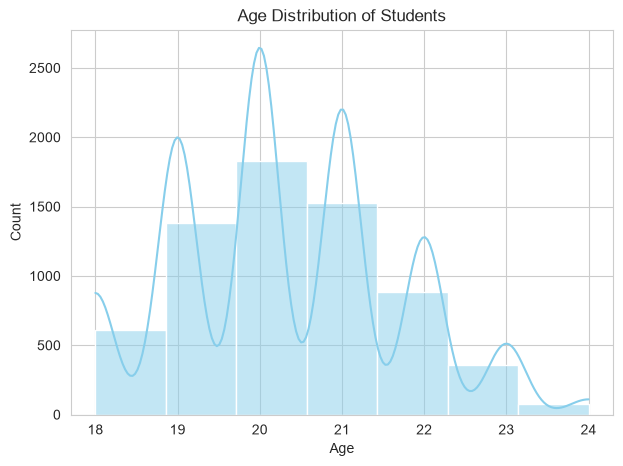

In [156]:
# Univariate Analysis - Age Distribution

plt.figure(figsize=(7,5))
sns.histplot(df["Age"], bins=7, kde=True, color="skyblue")
plt.title("Age Distribution of Students")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

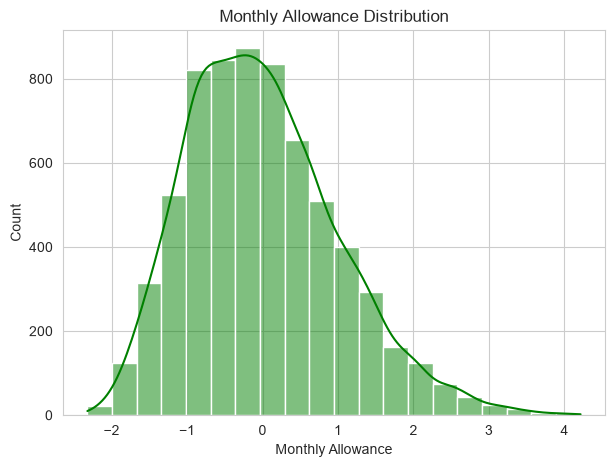

In [157]:
# Univariate Analysis - Monthly Allowance Distribution

plt.figure(figsize=(7,5))
sns.histplot(df["Monthly_Allowance"], bins=20, kde=True, color="green")
plt.title("Monthly Allowance Distribution")
plt.xlabel("Monthly Allowance")
plt.ylabel("Count")
plt.show()

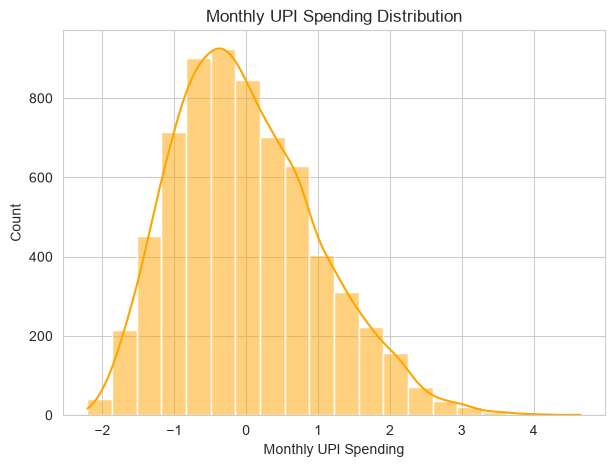

In [158]:
# Univariate Analysis - Monthly UPI Spending Distribution

plt.figure(figsize=(7,5))
sns.histplot(df["Monthly_UPI_Spending"], bins=20, kde=True, color="orange")
plt.title("Monthly UPI Spending Distribution")
plt.xlabel("Monthly UPI Spending")
plt.ylabel("Count")
plt.show()

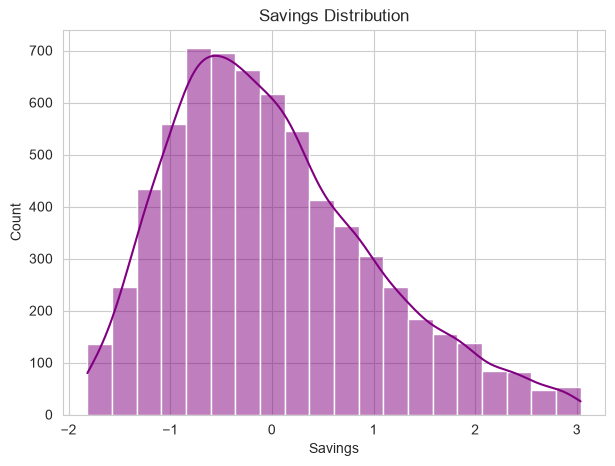

In [159]:
# Univariate Analysis - Savings Distribution

plt.figure(figsize=(7,5))
sns.histplot(df["Savings"], bins=20, kde=True, color="purple")
plt.title("Savings Distribution")
plt.xlabel("Savings")
plt.ylabel("Count")
plt.show()

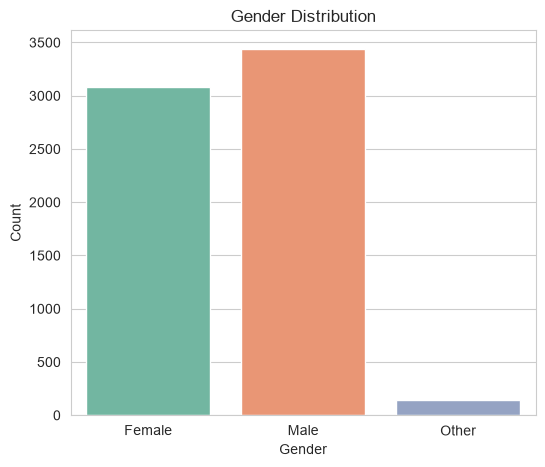

In [160]:
# Univariate Analysis - Gender Count Plot

df["Gender"] = (
    df["Gender"]
    .astype(str)
    .str.strip()
    .str.title()
)

df["Gender"] = df["Gender"].replace("Nan", np.nan)
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Gender", hue="Gender", palette="Set2", legend=False)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

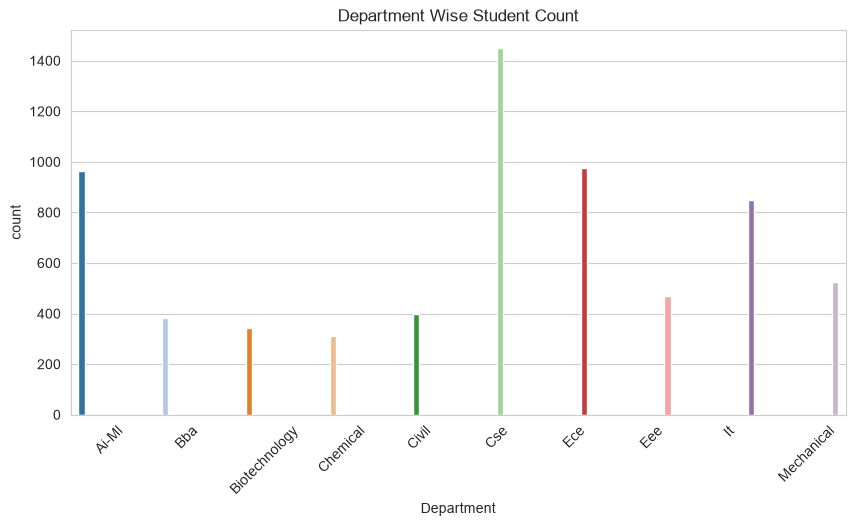

In [161]:
# Univariate Analysis - Department Count Plot

plt.figure(figsize=(10,5))
sns.countplot(data=df, x="Department", hue="Department", legend=False, palette="tab20")
plt.xticks(rotation=45)
plt.title("Department Wise Student Count")
plt.show()

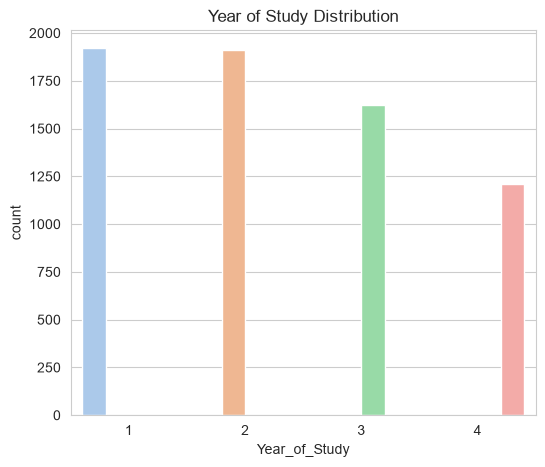

In [162]:
# Univariate Analysis - Year of Study Count Plot

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Year_of_Study", hue="Year_of_Study", legend=False, palette="pastel")
plt.title("Year of Study Distribution")
plt.show()

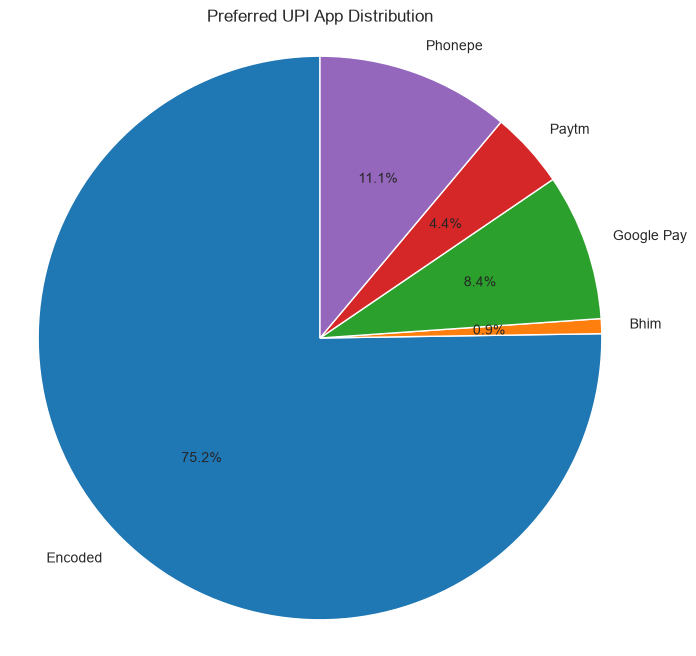

In [163]:
# Univariate Analysis - Preferred UPI App Pie Chart

app_columns = [col for col in df.columns if col.startswith("Preferred_UPI_App_")]

app_counts = df[app_columns].sum()

app_names = [col.replace("Preferred_UPI_App_", "") for col in app_columns]

plt.figure(figsize=(8,8))
plt.pie(app_counts, labels=app_names, autopct="%1.1f%%", startangle=90)
plt.title("Preferred UPI App Distribution")
plt.axis("equal")
plt.show()

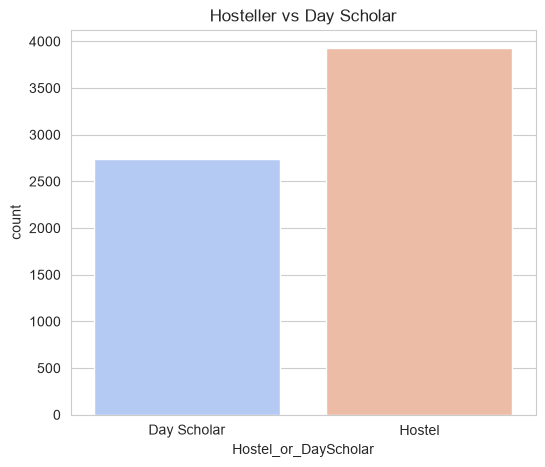

In [164]:
# Univariate Analysis - Hostel vs Day Scholar

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Hostel_or_DayScholar", hue="Hostel_or_DayScholar", legend=False, palette="coolwarm")
plt.title("Hosteller vs Day Scholar")
plt.show()

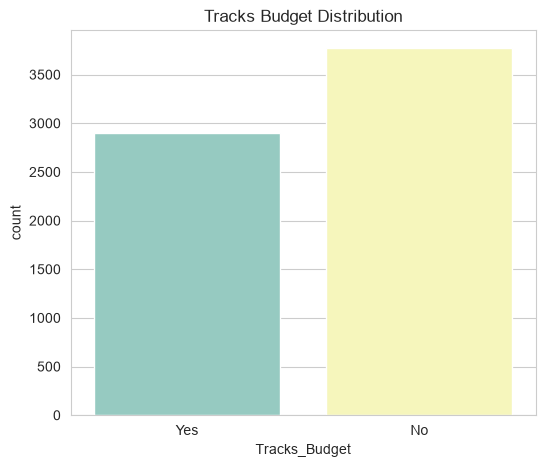

In [165]:
# Univariate Analysis - Tracks Budget Count Plot

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Tracks_Budget", hue="Tracks_Budget", legend=False, palette="Set3")
plt.title("Tracks Budget Distribution")
plt.show()

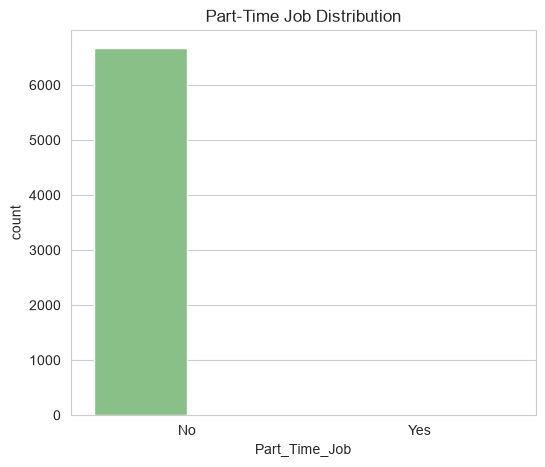

In [166]:
# Univariate Analysis - Part-Time Job Count Plot

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Part_Time_Job", hue="Part_Time_Job", legend=False, palette="Accent")
plt.title("Part-Time Job Distribution")
plt.show()

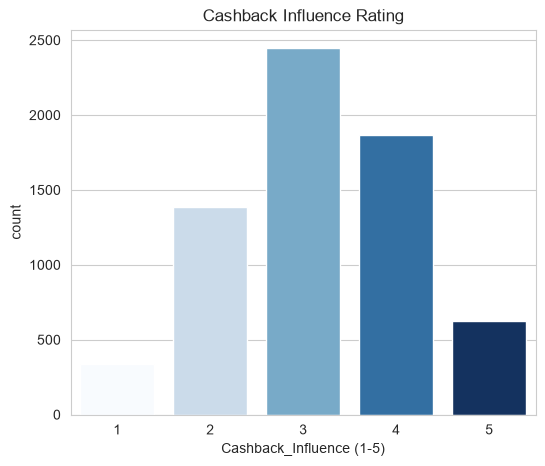

In [167]:
# Univariate Analysis - Cashback Influence Distribution

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Cashback_Influence (1-5)", hue="Cashback_Influence (1-5)", legend=False, palette="Blues")
plt.title("Cashback Influence Rating")
plt.show()

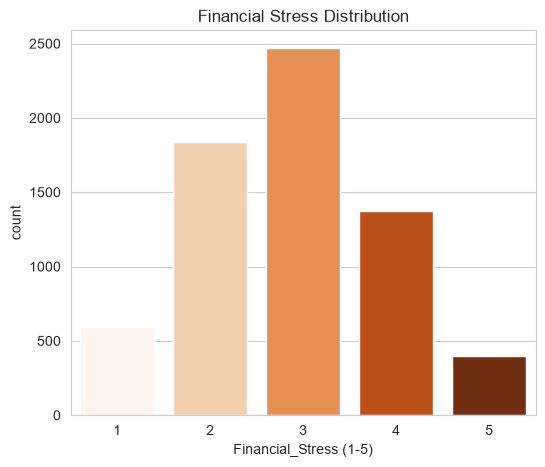

In [168]:
# Univariate Analysis - Financial Stress Distribution

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Financial_Stress (1-5)", hue="Financial_Stress (1-5)", legend=False, palette="Oranges")
plt.title("Financial Stress Distribution")
plt.show()

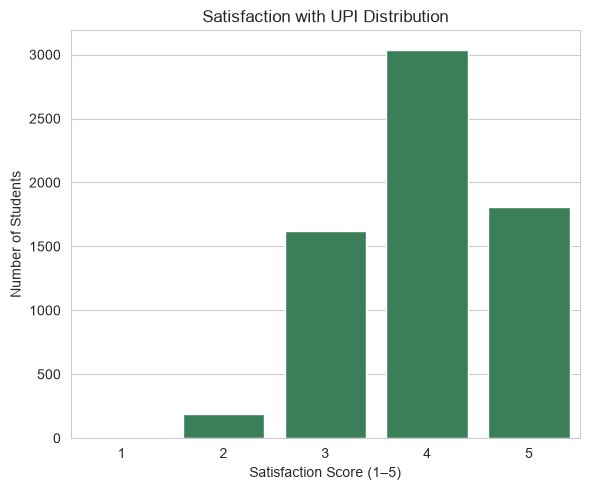

In [169]:
import matplotlib.pyplot as plt
import seaborn as sns

# Remove extra spaces around column names
df.columns = df.columns.str.strip()

# Find the satisfaction column
col = next(
    (c for c in df.columns if "Satisfaction_with_UPI" in c),
    None
)

if col is not None:
    plt.figure(figsize=(6, 5))
    sns.countplot(data=df, x=col, color="seagreen")
    plt.title("Satisfaction with UPI Distribution")
    plt.xlabel("Satisfaction Score (1–5)")
    plt.ylabel("Number of Students")
    plt.tight_layout()
    plt.show()
else:
    print("Satisfaction column not found. Check df.columns.tolist().")

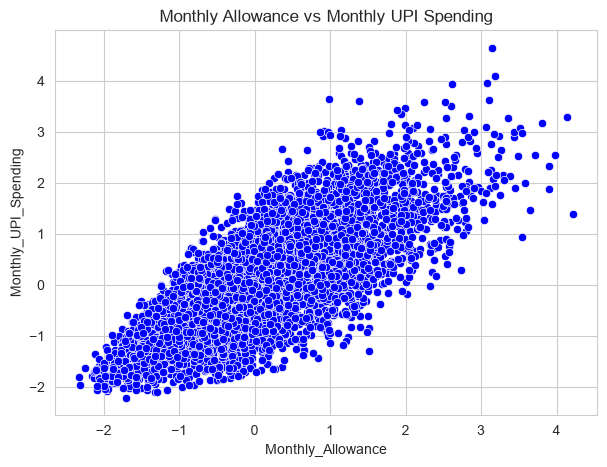

In [170]:
# Bivariate Analysis - Monthly Allowance vs Monthly UPI Spending

plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x="Monthly_Allowance", y="Monthly_UPI_Spending", color="blue")
plt.title("Monthly Allowance vs Monthly UPI Spending")
plt.show()

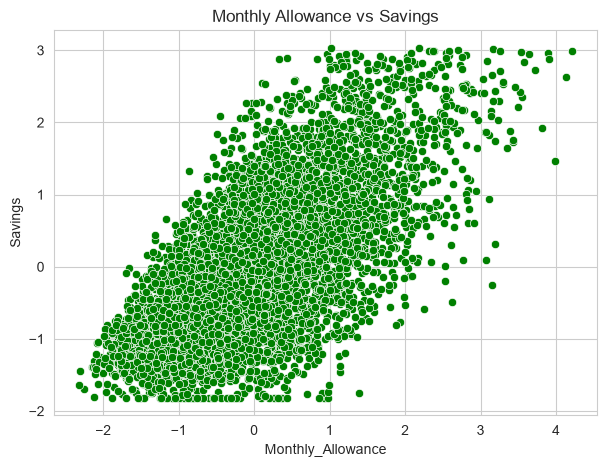

In [171]:
# Bivariate Analysis - Monthly Allowance vs Savings

plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x="Monthly_Allowance", y="Savings", color="green")
plt.title("Monthly Allowance vs Savings")
plt.show()

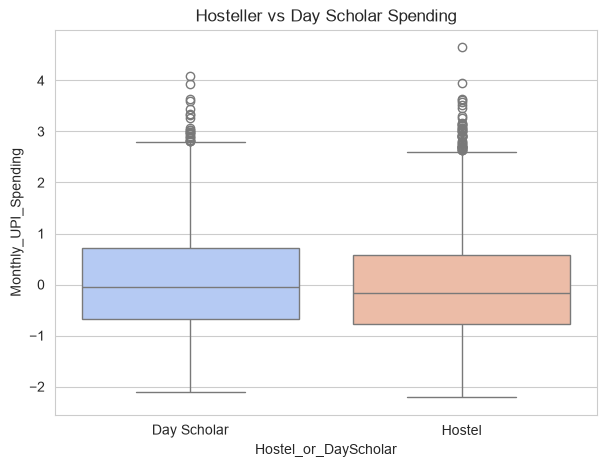

In [172]:
# Bivariate Analysis - Hostel vs Spending

plt.figure(figsize=(7,5))
sns.boxplot(data=df, x="Hostel_or_DayScholar", y="Monthly_UPI_Spending", hue="Hostel_or_DayScholar", legend=False, palette="coolwarm")
plt.title("Hosteller vs Day Scholar Spending")
plt.show()

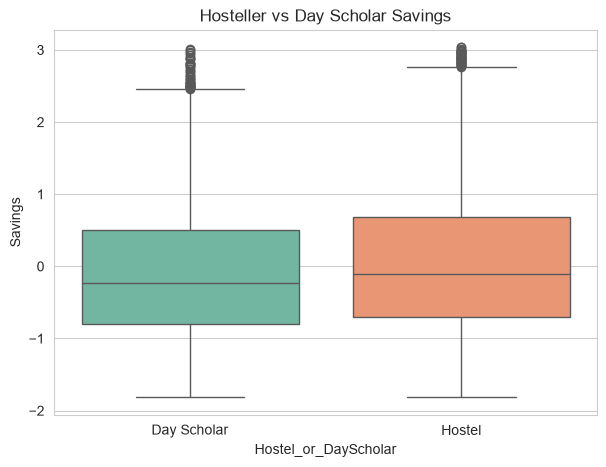

In [173]:
# Bivariate Analysis - Hostel vs Savings

plt.figure(figsize=(7,5))
sns.boxplot(data=df, x="Hostel_or_DayScholar", y="Savings", hue="Hostel_or_DayScholar", legend=False, palette="Set2")
plt.title("Hosteller vs Day Scholar Savings")
plt.show()

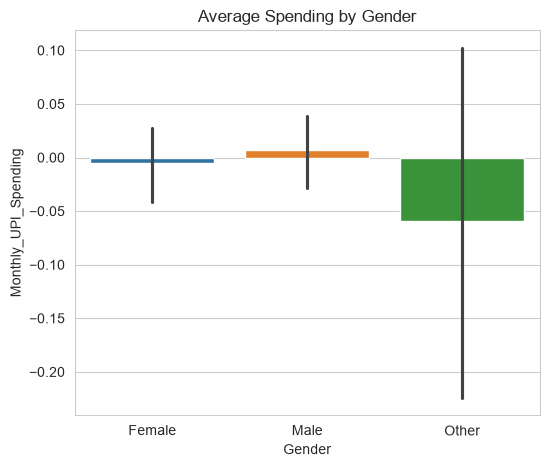

In [174]:
# Bivariate Analysis - Gender vs Spending

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Gender", y="Monthly_UPI_Spending", hue="Gender", legend=False)
plt.title("Average Spending by Gender")
plt.show()

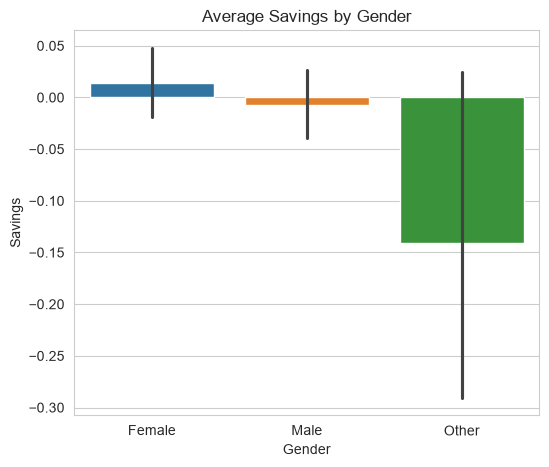

In [175]:
# Bivariate Analysis - Gender vs Savings

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Gender", y="Savings", hue="Gender", legend=False)
plt.title("Average Savings by Gender")
plt.show()

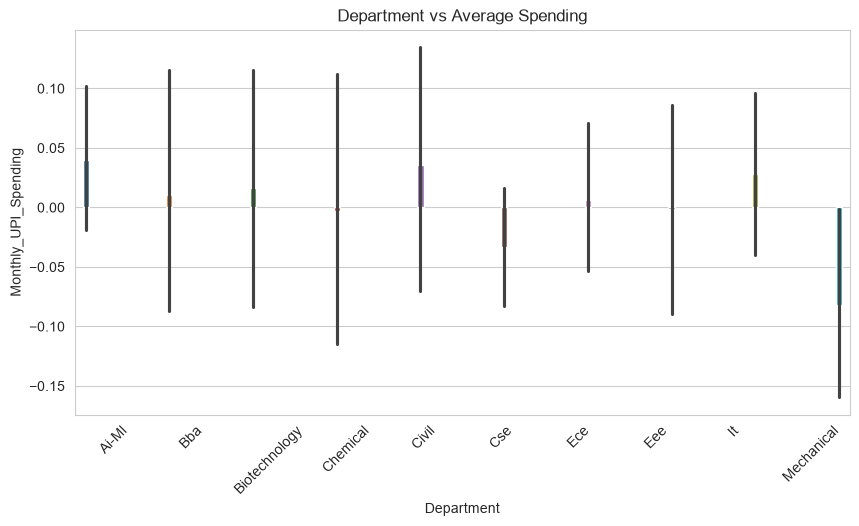

In [176]:
# Bivariate Analysis - Department vs Spending

plt.figure(figsize=(10,5))
sns.barplot(data=df, x="Department", y="Monthly_UPI_Spending", hue="Department", legend=False)
plt.xticks(rotation=45)
plt.title("Department vs Average Spending")
plt.show()

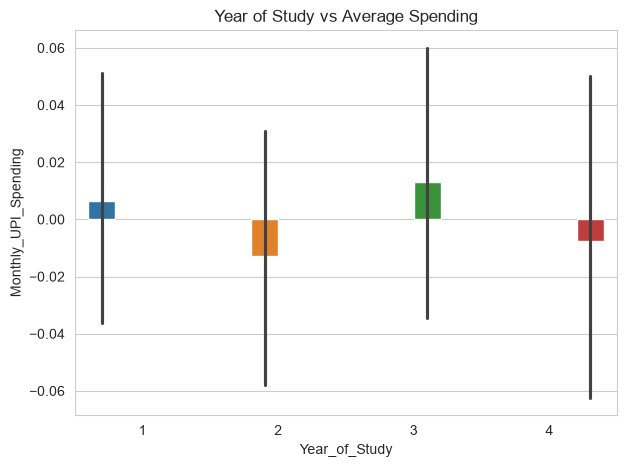

In [177]:
# Bivariate Analysis - Year of Study vs Spending

plt.figure(figsize=(7,5))
sns.barplot(data=df, x="Year_of_Study", y="Monthly_UPI_Spending", hue="Year_of_Study", legend=False)
plt.title("Year of Study vs Average Spending")
plt.show()

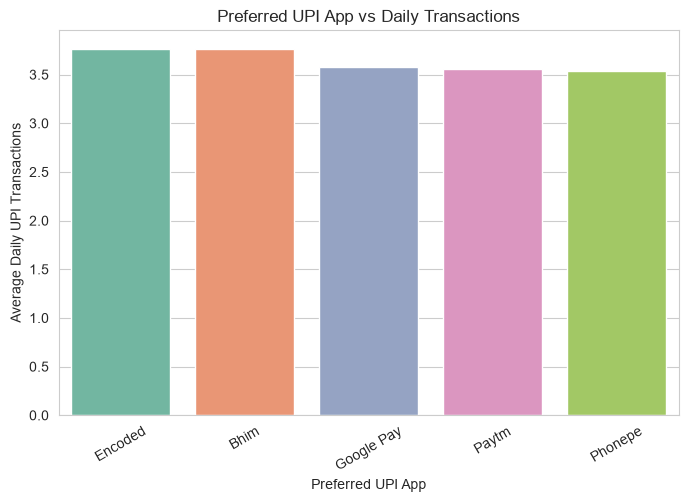

In [178]:
# Bivariate Analysis - Preferred UPI App vs Daily Transactions

plt.figure(figsize=(8,5))

if "Preferred_UPI_App" in df.columns:
    df["Preferred_UPI_App"] = (
        df["Preferred_UPI_App"]
        .astype(str)
        .str.strip()
        .str.title()
    )

    sns.barplot(
        data=df,
        x="Preferred_UPI_App",
        y="Daily_UPI_Transactions",
        estimator="mean",
        hue="Preferred_UPI_App",
        legend=False,
        palette="Set2"
    )

else:
    app_columns = [col for col in df.columns if col.startswith("Preferred_UPI_App_")]

    temp_df = pd.DataFrame({
        "Preferred_UPI_App": [col.replace("Preferred_UPI_App_", "") for col in app_columns],
        "Average_Transactions": [df.loc[df[col] == 1, "Daily_UPI_Transactions"].mean() for col in app_columns]
    })

    sns.barplot(
        data=temp_df,
        x="Preferred_UPI_App",
        y="Average_Transactions",
        hue="Preferred_UPI_App",
        legend=False,
        palette="Set2"
    )

plt.xticks(rotation=30)
plt.title("Preferred UPI App vs Daily Transactions")
plt.xlabel("Preferred UPI App")
plt.ylabel("Average Daily UPI Transactions")
plt.show()

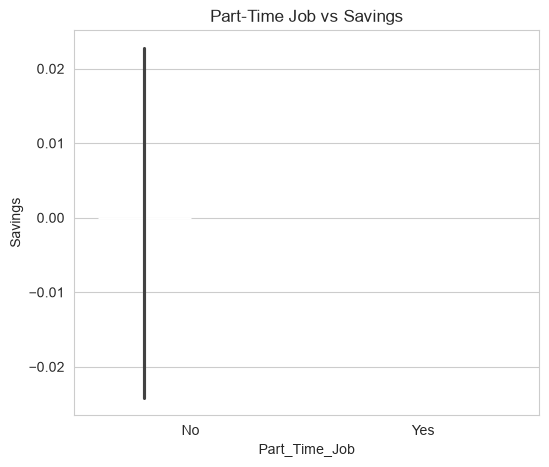

In [179]:
# Bivariate Analysis - Part-Time Job vs Savings

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Part_Time_Job", y="Savings", hue="Part_Time_Job", legend=False)
plt.title("Part-Time Job vs Savings")
plt.show()

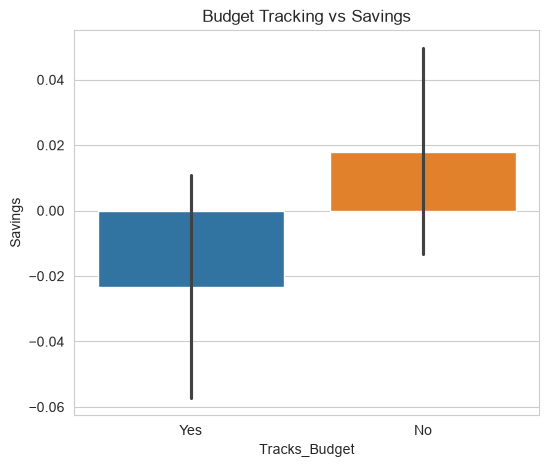

In [180]:
# Bivariate Analysis - Budget Tracking vs Savings

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Tracks_Budget", y="Savings", hue="Tracks_Budget", legend=False)
plt.title("Budget Tracking vs Savings")
plt.show()

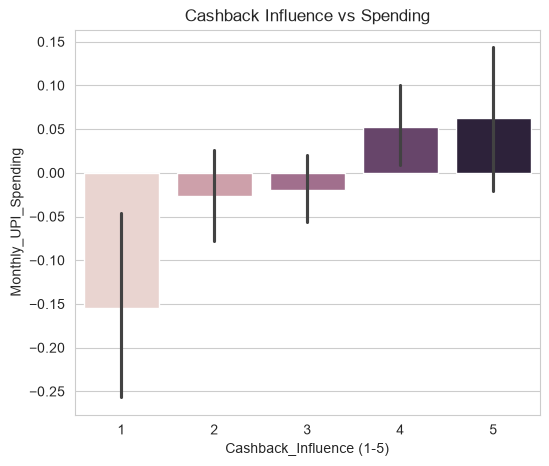

In [181]:
# Bivariate Analysis - Cashback Influence vs Spending

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Cashback_Influence (1-5)", y="Monthly_UPI_Spending", hue="Cashback_Influence (1-5)", legend=False)
plt.title("Cashback Influence vs Spending")
plt.show()

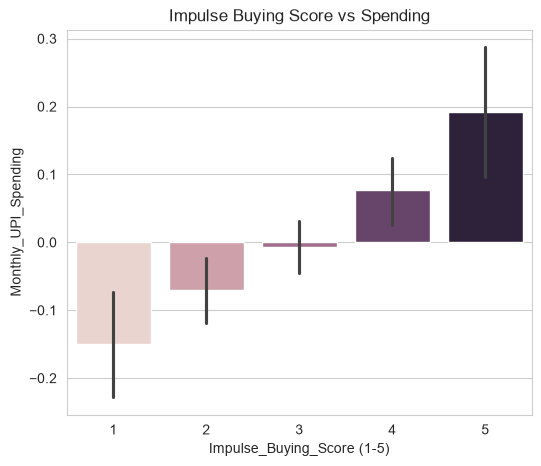

In [182]:
# Bivariate Analysis - Impulse Buying Score vs Spending

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Impulse_Buying_Score (1-5)", y="Monthly_UPI_Spending", hue="Impulse_Buying_Score (1-5)", legend=False)
plt.title("Impulse Buying Score vs Spending")
plt.show()

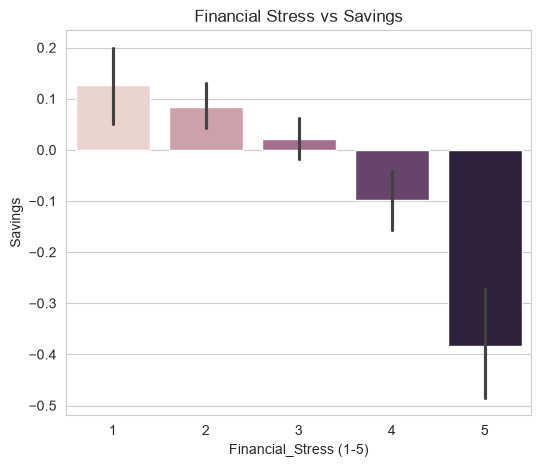

In [183]:
# Bivariate Analysis - Financial Stress vs Savings

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Financial_Stress (1-5)", y="Savings", hue="Financial_Stress (1-5)", legend=False)
plt.title("Financial Stress vs Savings")
plt.show()

In [184]:
# Bivariate Analysis - Satisfaction with UPI vs Spending

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Satisfaction_with_UPI (1-5)", y="Monthly_UPI_Spending", hue="Satisfaction_with_UPI (1-5)", legend=False)
plt.title("Satisfaction with UPI vs Spending")
plt.show()

ValueError: Could not interpret value `Satisfaction_with_UPI (1-5)` for `x`. An entry with this name does not appear in `data`.

<Figure size 600x500 with 0 Axes>

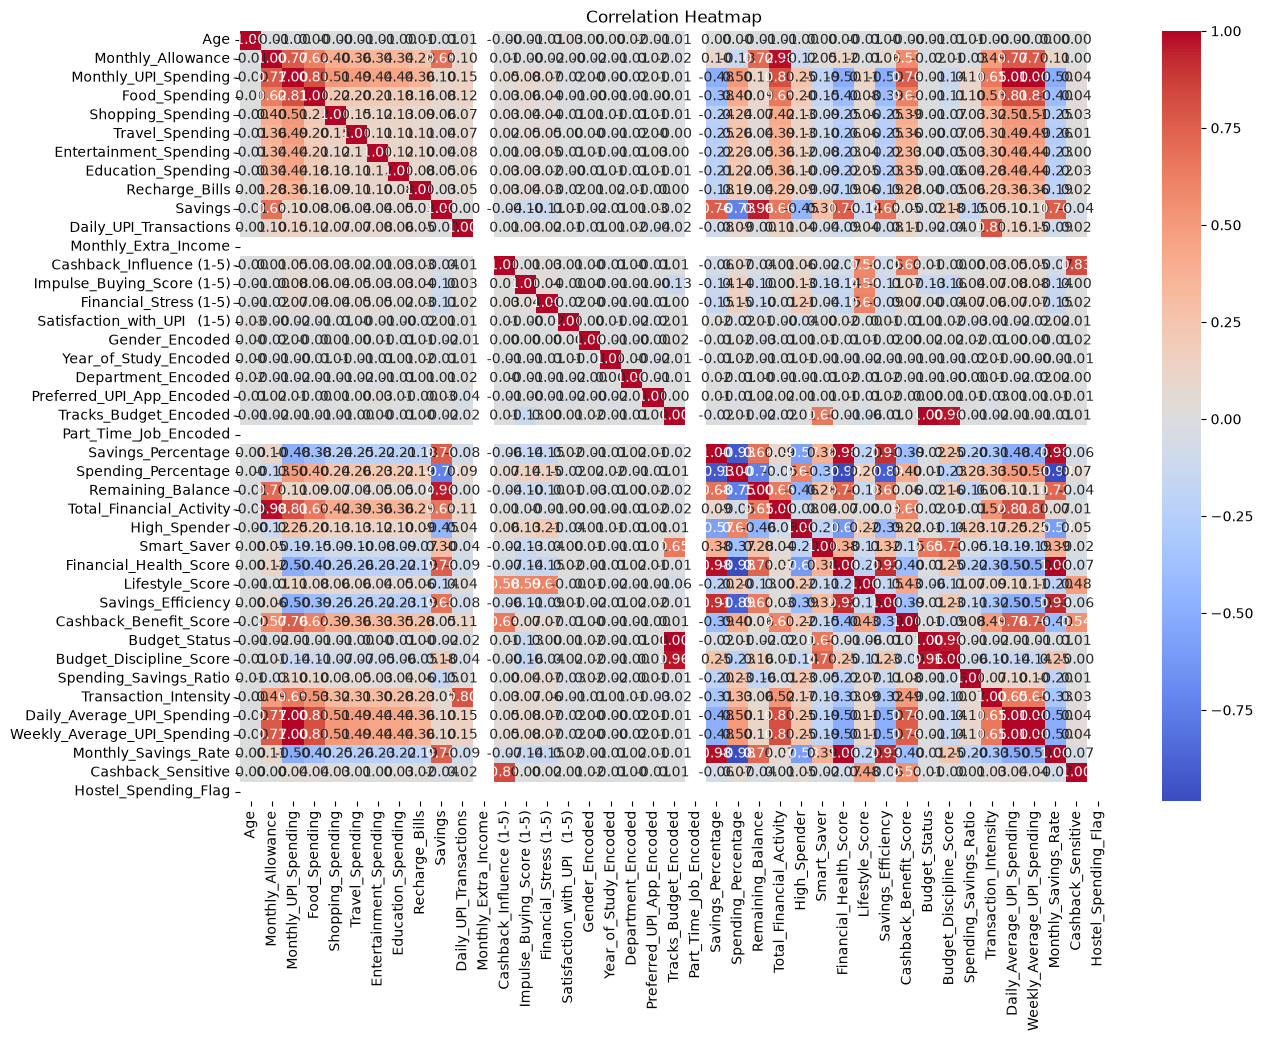

In [ ]:
# Multivariate Analysis - Correlation Heatmap

numeric_df = df.select_dtypes(include=["int64","float64"])

plt.figure(figsize=(14,10))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

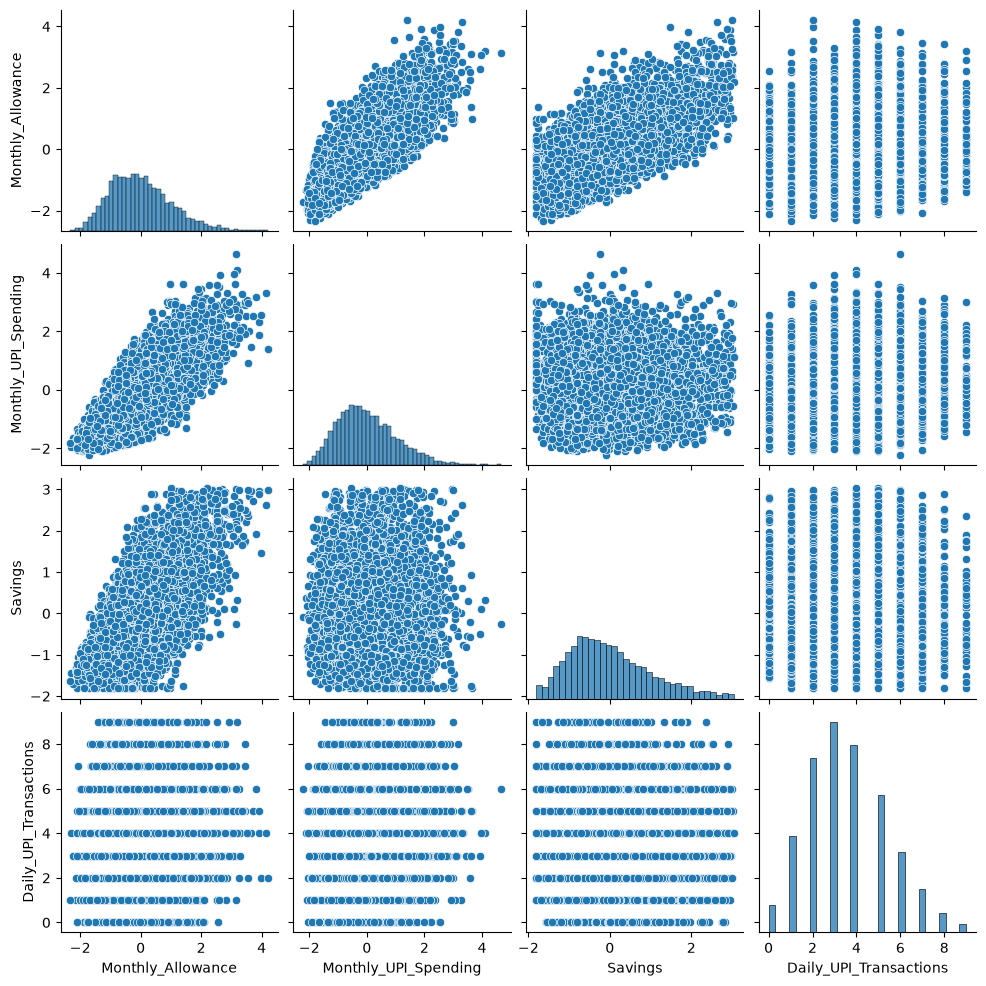

In [ ]:
# Multivariate Analysis - Pair Plot

pair_columns = [
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings",
    "Daily_UPI_Transactions"
]

sns.pairplot(df[pair_columns].dropna())
plt.show()

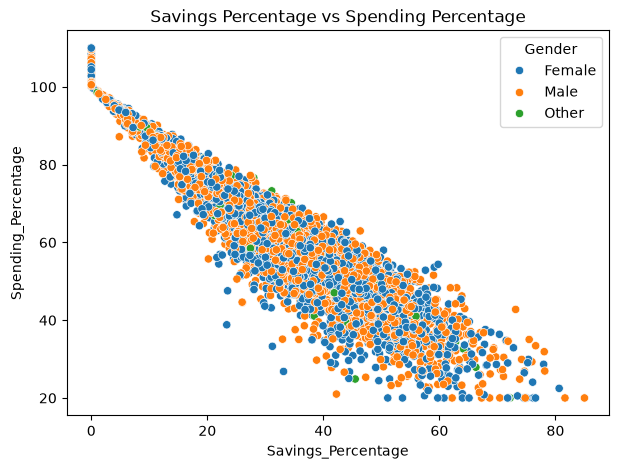

In [ ]:
# Multivariate Analysis - Savings Percentage vs Spending Percentage

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x="Savings_Percentage",
    y="Spending_Percentage",
    hue="Gender"
)
plt.title("Savings Percentage vs Spending Percentage")
plt.show()

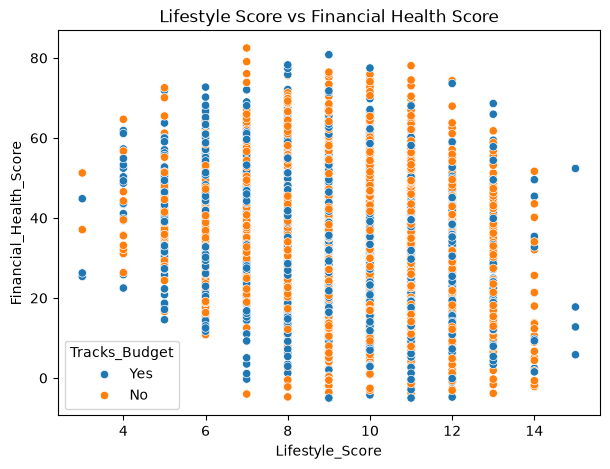

In [ ]:
# Multivariate Analysis - Lifestyle Score vs Financial Health Score

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x="Lifestyle_Score",
    y="Financial_Health_Score",
    hue="Tracks_Budget"
)
plt.title("Lifestyle Score vs Financial Health Score")
plt.show()

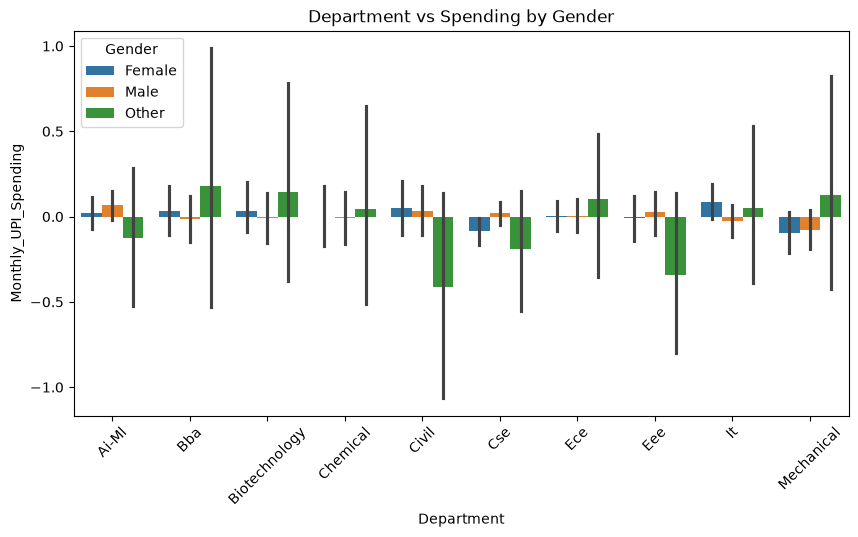

In [ ]:
# Multivariate Analysis - Department vs Spending by Gender

plt.figure(figsize=(10,5))
sns.barplot(
    data=df,
    x="Department",
    y="Monthly_UPI_Spending",
    hue="Gender"
)
plt.xticks(rotation=45)
plt.title("Department vs Spending by Gender")
plt.show()

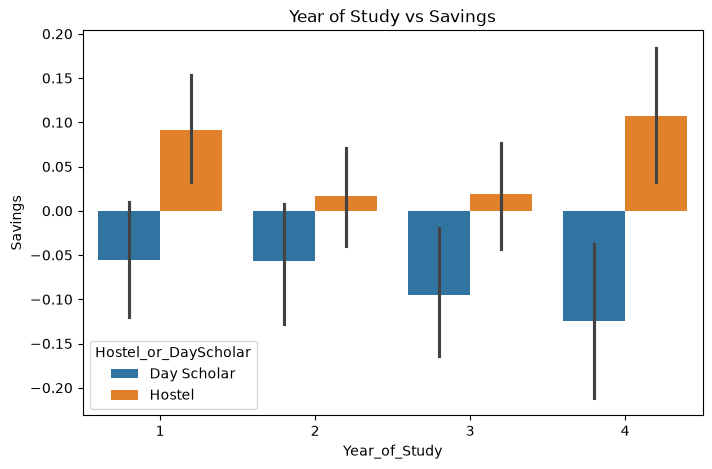

In [ ]:
# Multivariate Analysis - Year of Study vs Savings

plt.figure(figsize=(8,5))
sns.barplot(
    data=df,
    x="Year_of_Study",
    y="Savings",
    hue="Hostel_or_DayScholar"
)
plt.title("Year of Study vs Savings")
plt.show()

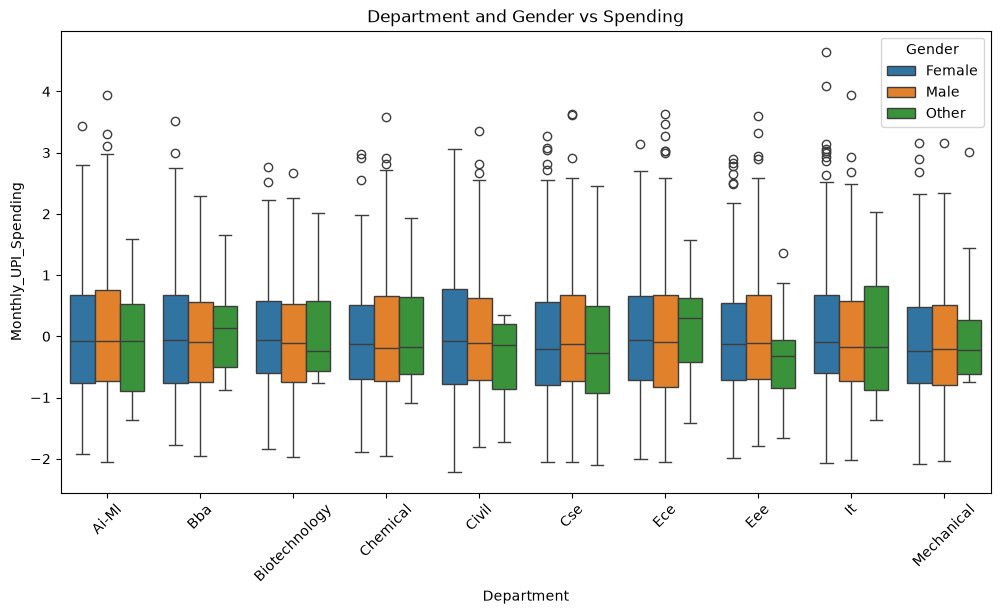

In [ ]:
# Multivariate Analysis - Spending Distribution by Department and Gender

plt.figure(figsize=(12,6))
sns.boxplot(
    data=df,
    x="Department",
    y="Monthly_UPI_Spending",
    hue="Gender"
)
plt.xticks(rotation=45)
plt.title("Department and Gender vs Spending")
plt.show()

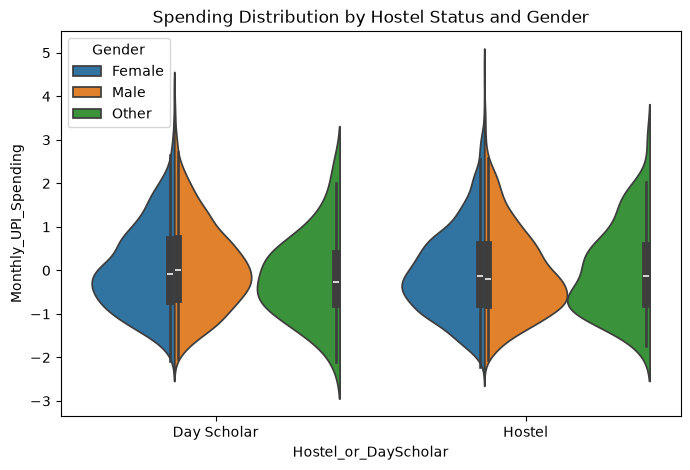

In [ ]:
# Multivariate Analysis - Spending Distribution by Hostel Status

plt.figure(figsize=(8,5))
sns.violinplot(
    data=df,
    x="Hostel_or_DayScholar",
    y="Monthly_UPI_Spending",
    hue="Gender",
    split=True
)
plt.title("Spending Distribution by Hostel Status and Gender")
plt.show()

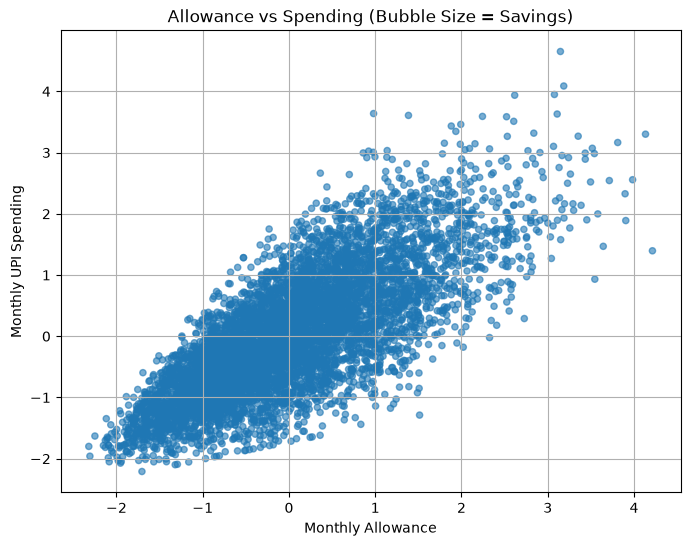

In [ ]:
# Multivariate Analysis - Bubble Plot

bubble_df = df[["Monthly_Allowance", "Monthly_UPI_Spending", "Savings"]].copy()

bubble_df["Monthly_Allowance"] = bubble_df["Monthly_Allowance"].fillna(
    bubble_df["Monthly_Allowance"].median()
)

bubble_df["Monthly_UPI_Spending"] = bubble_df["Monthly_UPI_Spending"].fillna(
    bubble_df["Monthly_UPI_Spending"].median()
)

bubble_df["Savings"] = bubble_df["Savings"].fillna(
    bubble_df["Savings"].median()
)

bubble_size = (bubble_df["Savings"].abs() / 10) + 20

plt.figure(figsize=(8,6))

plt.scatter(
    bubble_df["Monthly_Allowance"],
    bubble_df["Monthly_UPI_Spending"],
    s=bubble_size,
    alpha=0.6
)

plt.xlabel("Monthly Allowance")
plt.ylabel("Monthly UPI Spending")
plt.title("Allowance vs Spending (Bubble Size = Savings)")
plt.grid(True)

plt.show()

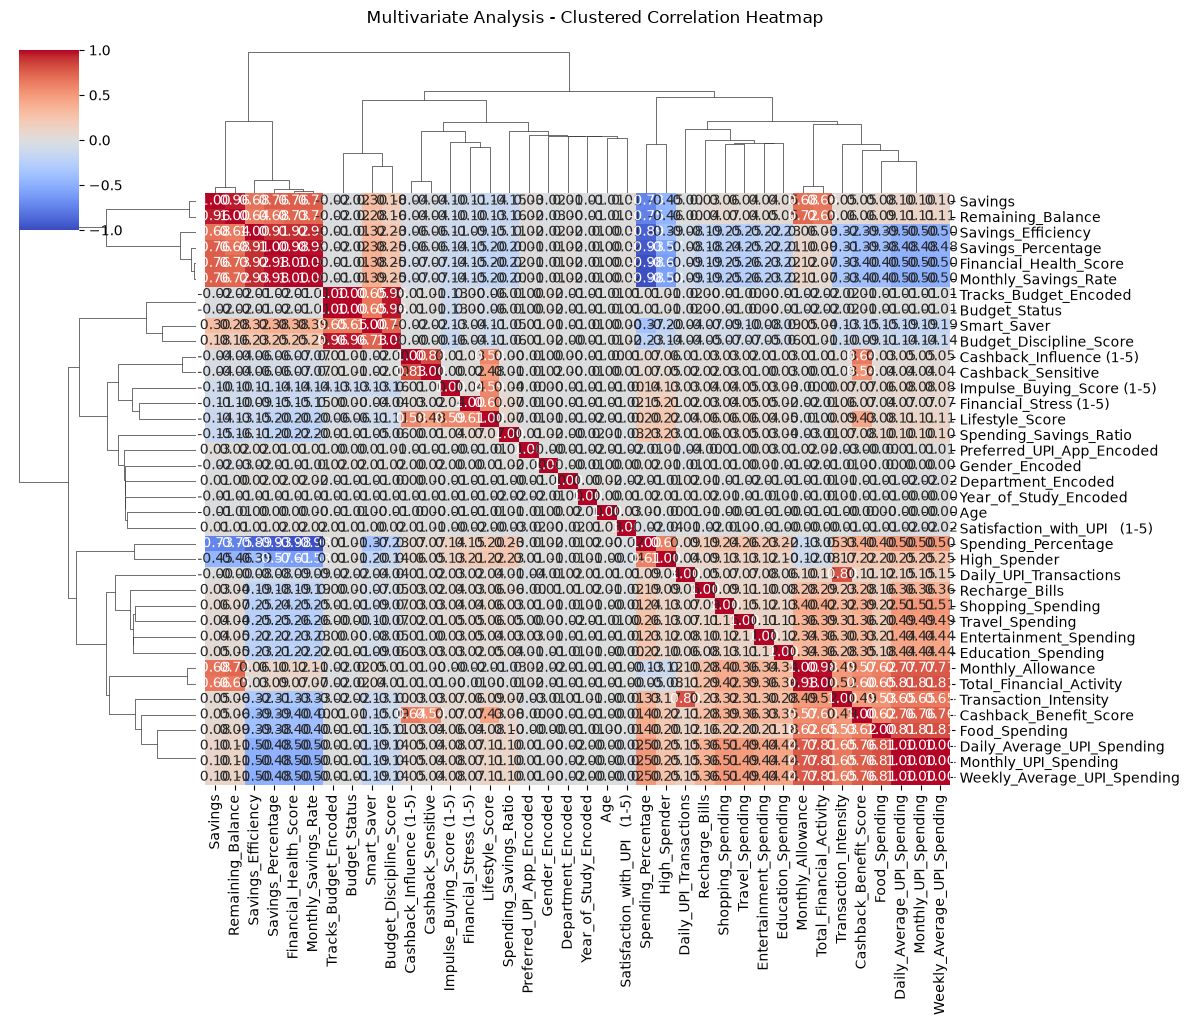

In [ ]:
# Multivariate Analysis - Clustered Heatmap


import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select numeric columns
numeric_df = df.select_dtypes(include="number").copy()

# Remove columns with no variation
numeric_df = numeric_df.loc[:, numeric_df.nunique(dropna=True) > 1]

# Calculate correlation and handle missing/infinite values
corr_matrix = numeric_df.corr()
corr_matrix = corr_matrix.replace([np.inf, -np.inf], np.nan)
corr_matrix = corr_matrix.dropna(axis=0, how="any")
corr_matrix = corr_matrix.dropna(axis=1, how="any")

# Generate clustered heatmap
if corr_matrix.shape[0] >= 2:
    sns.clustermap(
        corr_matrix,
        cmap="coolwarm",
        annot=True,
        fmt=".2f",
        figsize=(12, 10),
        vmin=-1,
        vmax=1,
        center=0
    )
    plt.suptitle("Multivariate Analysis - Clustered Correlation Heatmap", y=1.02)
    plt.show()
else:
    print("Not enough valid numeric columns to create a clustered heatmap.")


Department with Highest Average UPI Spending:
Department
Ai-Ml            0.040034
Civil            0.035493
It               0.028355
Biotechnology    0.016514
Bba              0.010106
Name: Monthly_UPI_Spending, dtype: float64


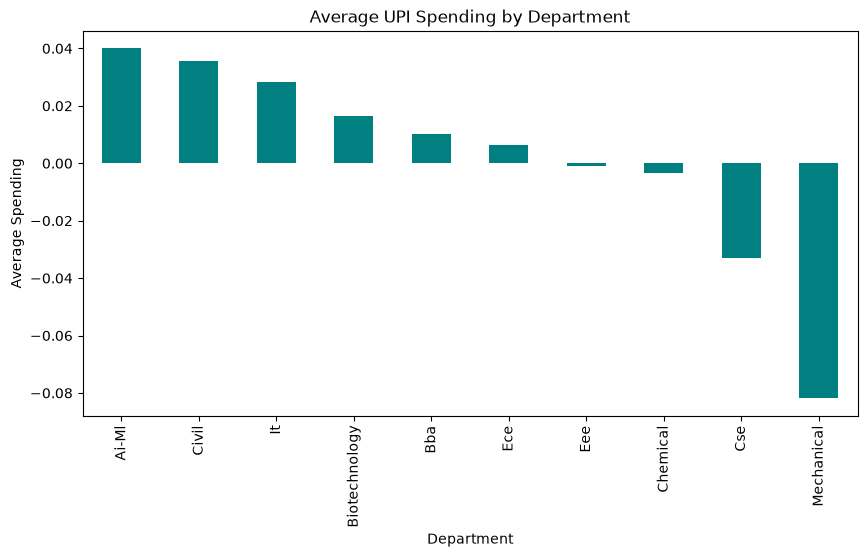

In [ ]:
# Insight 1 - Highest Spending Department

department_spending = df.groupby("Department")["Monthly_UPI_Spending"].mean().sort_values(ascending=False)

print("Department with Highest Average UPI Spending:")
print(department_spending.head())

plt.figure(figsize=(10,5))
department_spending.plot(kind="bar", color="teal")
plt.title("Average UPI Spending by Department")
plt.xlabel("Department")
plt.ylabel("Average Spending")
plt.show()

Most Preferred UPI App:
  Preferred_UPI_App  Count
0           Encoded  18158
1           Phonepe   2679
2        Google Pay   2031
3             Paytm   1058
4              Bhim    206


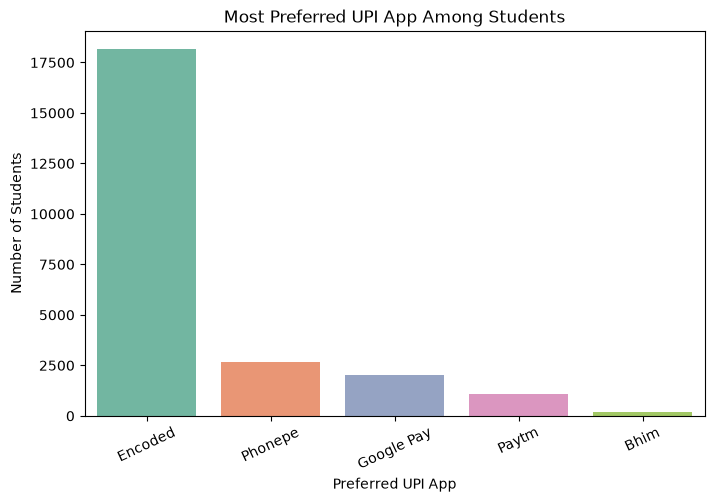

In [ ]:
# Insight 2 - Most Preferred UPI App

plt.figure(figsize=(8,5))

if "Preferred_UPI_App" in df.columns:

    df["Preferred_UPI_App"] = (
        df["Preferred_UPI_App"]
        .astype(str)
        .str.strip()
        .str.title()
    )

    df["Preferred_UPI_App"] = df["Preferred_UPI_App"].replace("Nan", np.nan)
    df["Preferred_UPI_App"] = df["Preferred_UPI_App"].fillna(df["Preferred_UPI_App"].mode()[0])

    upi_count = df["Preferred_UPI_App"].value_counts()

    print("Most Preferred UPI App:")
    print(upi_count)

    sns.countplot(
        data=df,
        x="Preferred_UPI_App",
        hue="Preferred_UPI_App",
        legend=False,
        palette="Set2"
    )

else:

    app_columns = [col for col in df.columns if col.startswith("Preferred_UPI_App_")]

    app_count = df[app_columns].sum().sort_values(ascending=False)

    app_df = pd.DataFrame({
        "Preferred_UPI_App": app_count.index.str.replace("Preferred_UPI_App_", "", regex=False),
        "Count": app_count.values
    })

    print("Most Preferred UPI App:")
    print(app_df)

    sns.barplot(
        data=app_df,
        x="Preferred_UPI_App",
        y="Count",
        hue="Preferred_UPI_App",
        legend=False,
        palette="Set2"
    )

plt.title("Most Preferred UPI App Among Students")
plt.xticks(rotation=25)
plt.xlabel("Preferred UPI App")
plt.ylabel("Number of Students")
plt.show()

Gender
Female               0.022514
Male                -0.021561
Prefer Not To Say   -0.095020
Name: Monthly_UPI_Spending, dtype: float64


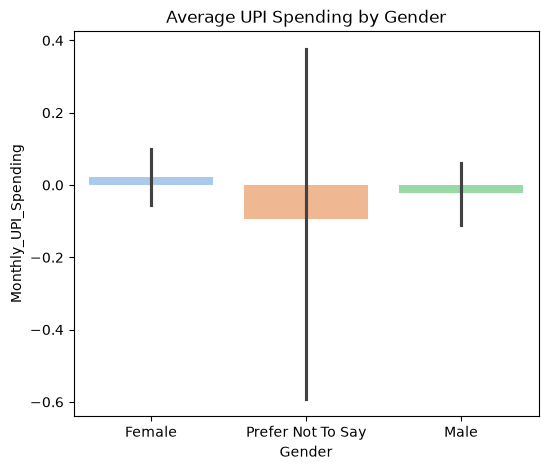

In [ ]:
# Insight 3 - Average Spending by Gender

gender_spending = df.groupby("Gender")["Monthly_UPI_Spending"].mean()

print(gender_spending)

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Gender", y="Monthly_UPI_Spending", hue="Gender", legend=False, palette="pastel")
plt.title("Average UPI Spending by Gender")
plt.show()

Hostel_or_DayScholar
Day Scholar    0.057802
Hostel        -0.040261
Name: Monthly_UPI_Spending, dtype: float64


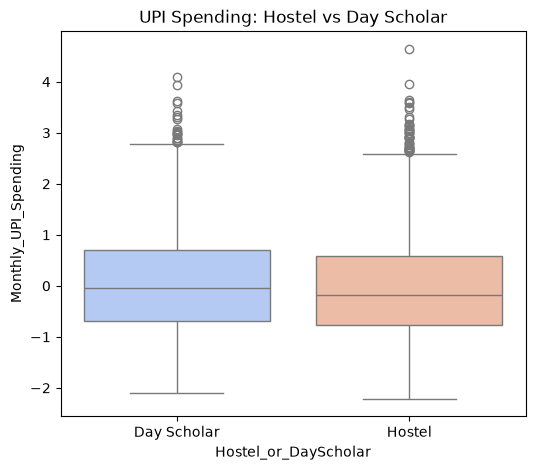

In [ ]:
# Insight 4 - Hostel vs Day Scholar Spending

hostel_spending = df.groupby("Hostel_or_DayScholar")["Monthly_UPI_Spending"].mean()

print(hostel_spending)

plt.figure(figsize=(6,5))
sns.boxplot(data=df, x="Hostel_or_DayScholar", y="Monthly_UPI_Spending", hue="Hostel_or_DayScholar", legend=False, palette="coolwarm")
plt.title("UPI Spending: Hostel vs Day Scholar")
plt.show()

Tracks_Budget
No     0.026214
Yes   -0.028518
Name: Savings, dtype: float64


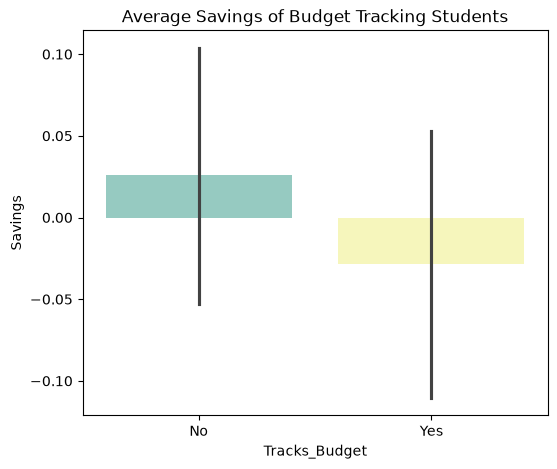

In [ ]:
# Insight 5 - Budget Tracking and Savings

budget_savings = df.groupby("Tracks_Budget")["Savings"].mean()

print(budget_savings)

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Tracks_Budget", y="Savings", hue="Tracks_Budget", legend=False, palette="Set3")
plt.title("Average Savings of Budget Tracking Students")
plt.show()

Cashback_Influence (1-5)
1   -0.154592
2   -0.026562
3   -0.019923
4    0.052872
5    0.062362
Name: Monthly_UPI_Spending, dtype: float64


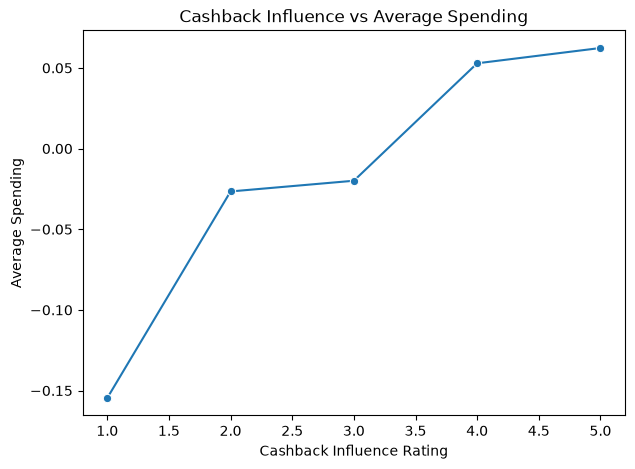

In [ ]:
# Insight 6 - Cashback Influence on Spending

cashback_spending = df.groupby("Cashback_Influence (1-5)")["Monthly_UPI_Spending"].mean()

print(cashback_spending)

plt.figure(figsize=(7,5))
sns.lineplot(x=cashback_spending.index, y=cashback_spending.values, marker="o")
plt.title("Cashback Influence vs Average Spending")
plt.xlabel("Cashback Influence Rating")
plt.ylabel("Average Spending")
plt.show()

Impulse_Buying_Score (1-5)
1   -0.150405
2   -0.069664
3   -0.007133
4    0.076975
5    0.191931
Name: Monthly_UPI_Spending, dtype: float64


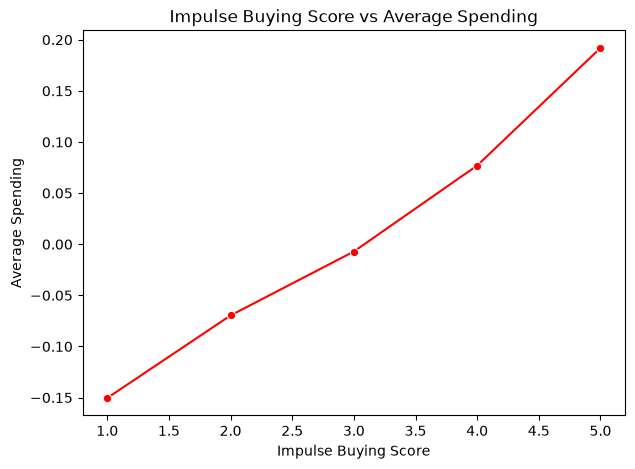

In [ ]:
# Insight 7 - Impulse Buying and Spending

impulse_spending = df.groupby("Impulse_Buying_Score (1-5)")["Monthly_UPI_Spending"].mean()

print(impulse_spending)

plt.figure(figsize=(7,5))
sns.lineplot(x=impulse_spending.index, y=impulse_spending.values, marker="o", color="red")
plt.title("Impulse Buying Score vs Average Spending")
plt.xlabel("Impulse Buying Score")
plt.ylabel("Average Spending")
plt.show()

Financial_Stress (1-5)
1    0.108258
2    0.051188
3   -0.106938
4   -0.055172
5    0.000709
Name: Savings, dtype: float64


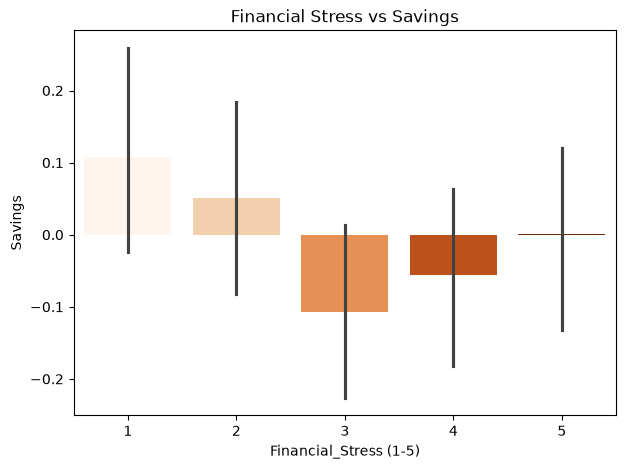

In [ ]:
# Insight 8 - Financial Stress and Savings

stress_savings = df.groupby("Financial_Stress (1-5)")["Savings"].mean()

print(stress_savings)

plt.figure(figsize=(7,5))
sns.barplot(data=df, x="Financial_Stress (1-5)", y="Savings", hue="Financial_Stress (1-5)", legend=False, palette="Oranges")
plt.title("Financial Stress vs Savings")
plt.show()

Year_of_Study
1    0.006437
2   -0.012893
3    0.013112
4   -0.007431
Name: Monthly_UPI_Spending, dtype: float64


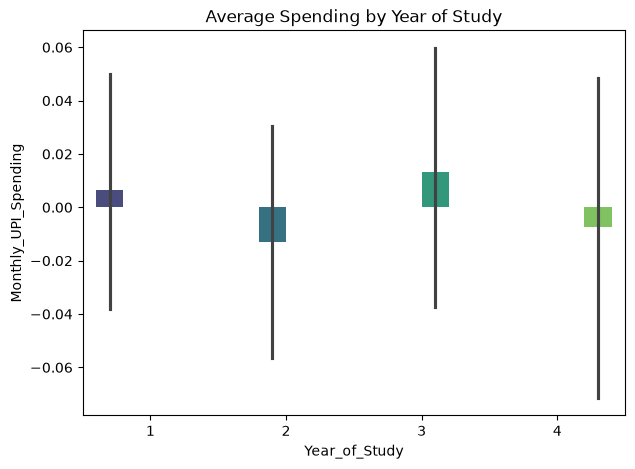

In [ ]:
# Insight 9 - Year of Study Spending Trend

year_spending = df.groupby("Year_of_Study")["Monthly_UPI_Spending"].mean()

print(year_spending)

plt.figure(figsize=(7,5))
sns.barplot(data=df, x="Year_of_Study", y="Monthly_UPI_Spending", hue="Year_of_Study", legend=False, palette="viridis")
plt.title("Average Spending by Year of Study")
plt.show()

Correlation between Monthly Allowance and UPI Spending: 0.77


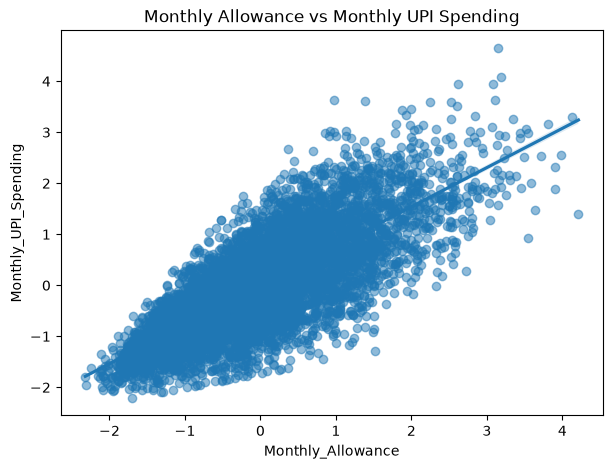

In [ ]:
# Insight 10 - Correlation Between Allowance and Spending

correlation = df["Monthly_Allowance"].corr(df["Monthly_UPI_Spending"])

print("Correlation between Monthly Allowance and UPI Spending:", round(correlation,2))

plt.figure(figsize=(7,5))
sns.regplot(data=df, x="Monthly_Allowance", y="Monthly_UPI_Spending", scatter_kws={"alpha":0.5})
plt.title("Monthly Allowance vs Monthly UPI Spending")
plt.show()

In [ ]:
# Recommendation 1 - Students with Low Savings

low_savers = df[df["Savings_Percentage"] < 20]

print("Number of Low Saving Students:", len(low_savers))

low_savers[["Student_ID","Savings_Percentage"]].head()

Number of Low Saving Students: 1160


,Student_ID,Savings_Percentage
10,Stu000011,14.41
13,Stu000014,3.89
14,Stu000015,9.59
25,Stu000026,10.58
29,Stu000030,16.38


In [ ]:
# Recommendation 2 - High Spenders

high_spenders = df[df["Spending_Percentage"] > 80]

print("Number of High Spenders:", len(high_spenders))

high_spenders[["Student_ID","Spending_Percentage"]].head()

Number of High Spenders: 732


,Student_ID,Spending_Percentage
13,Stu000014,95.26
14,Stu000015,87.47
25,Stu000026,88.59
73,Stu000074,91.81
124,Stu000125,106.88


In [ ]:
# Recommendation 3 - Budget Conscious Students

budget_students = df[df["Tracks_Budget"] == "Yes"]

print("Average Savings:", budget_students["Savings"].mean())

budget_students[["Student_ID","Savings"]].head()

Average Savings: -0.023356961834753446


,Student_ID,Savings
0,Stu000001,-0.283345
9,Stu000010,2.026203
10,Stu000011,-1.115468
12,Stu000013,-1.014689
17,Stu000018,2.163231


In [ ]:
# Recommendation 4 - Cashback Sensitive Students

cashback_students = df[df["Cashback_Influence (1-5)"] >= 4]

print("Average Spending:", cashback_students["Monthly_UPI_Spending"].mean())

cashback_students[["Student_ID","Cashback_Influence (1-5)"]].head()

Average Spending: 0.05524202295311212


,Student_ID,Cashback_Influence (1-5)
3,Stu000004,4
10,Stu000011,4
12,Stu000013,4
17,Stu000018,4
25,Stu000026,4


In [ ]:
# Recommendation 5 - High Financial Stress Students

stress_students = df[df["Financial_Stress (1-5)"] >= 4]

print("Average Savings:", stress_students["Savings"].mean())

stress_students[["Student_ID","Financial_Stress (1-5)"]].head()

Average Savings: -0.1616365133606806


,Student_ID,Financial_Stress (1-5)
0,Stu000001,4
11,Stu000012,4
12,Stu000013,4
13,Stu000014,5
14,Stu000015,5


In [ ]:
# Recommendation 6 - High Impulse Buying Students

impulse_students = df[df["Impulse_Buying_Score (1-5)"] >= 4]

print("Average Spending:", impulse_students["Monthly_UPI_Spending"].mean())

impulse_students[["Student_ID","Impulse_Buying_Score (1-5)"]].head()

Average Spending: 0.10104339770015783


,Student_ID,Impulse_Buying_Score (1-5)
10,Stu000011,4
11,Stu000012,4
12,Stu000013,4
14,Stu000015,4
17,Stu000018,4


In [ ]:
# Recommendation 7 - Excellent Financial Health Students

excellent_students = df[df["Financial_Health_Score"] >= 75]

print("Number of Excellent Financial Health Students:", len(excellent_students))

excellent_students[["Student_ID","Financial_Health_Score"]].head()

Number of Excellent Financial Health Students: 15


,Student_ID,Financial_Health_Score
1150,Stu001151,75.19
1222,Stu001223,76.00
2966,Stu002967,76.09
3633,Stu003634,77.28
4771,Stu004772,78.08


In [ ]:
# Recommendation 8 - Hostel Students Spending More Than Average

average_spending = df["Monthly_UPI_Spending"].mean()

hostel_high = df[
    (df["Hostel_or_DayScholar"] == "Hosteller") &
    (df["Monthly_UPI_Spending"] > average_spending)
]

print("Hostel Students Spending Above Average:", len(hostel_high))

hostel_high[["Student_ID","Monthly_UPI_Spending"]].head()

Hostel Students Spending Above Average: 0


,Student_ID,Monthly_UPI_Spending


In [ ]:
# Recommendation 9 - Students Saving More Than 30 Percent

good_savers = df[df["Savings_Percentage"] >= 30]

print("Number of Good Savers:", len(good_savers))

good_savers[["Student_ID","Savings_Percentage"]].head()

Number of Good Savers: 3879


,Student_ID,Savings_Percentage
0,Stu000001,40.90
9,Stu000010,46.17
11,Stu000012,51.77
17,Stu000018,49.89
20,Stu000021,36.03


In [ ]:
# Recommendation 10 - Top 10 Smart Savers

top_savers = df.sort_values("Financial_Health_Score", ascending=False).head(10)

print(top_savers[[
    "Student_ID",
    "Savings_Percentage",
    "Financial_Health_Score"
]])

      Student_ID  Savings_Percentage  Financial_Health_Score
9301   Stu009302               85.00                   82.50
9193   Stu009194               81.64                   80.82
11619  Stu011620               80.64                   79.09
11557  Stu011558               76.57                   78.28
4771   Stu004772               76.16                   78.08
6332   Stu006333               75.01                   77.50
11106  Stu011107               74.79                   77.40
3633   Stu003634               74.54                   77.28
8674   Stu008675               73.46                   76.46
2966   Stu002967               72.18                   76.09


# PART 2 : EXPLORATORY DATA ANALYSIS (EDA)

Preprocessing is completed in Part 1. In this part we explore the cleaned data
using graphs and write down what we understand from each graph.

**Small note about the data used here**

In Phase 17 and Phase 18 we normalised and standardised `Monthly_Allowance`,
`Monthly_UPI_Spending` and `Savings`. After that these columns became z-scores
(values like -1.22, 0.47) instead of rupees. Graphs in rupees are much easier to
explain in the report, so in the next cell we bring back the original rupee values
from the raw CSV into three **new** columns:

* `Allowance_INR`
* `Spending_INR`
* `Savings_INR`

We also rebuild a single `UPI_App` column, because One Hot Encoding with
`drop_first=True` removed one app from the dummy columns.

None of the earlier code or columns is changed or deleted.

In [ ]:

import pandas as pd
import numpy as np

# Load the original, unscaled dataset
raw = pd.read_csv("upi_spending_analysis_11620_records.csv")

# Check that the expected columns exist
required = [
    "Student_ID",
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings",
    "Preferred_UPI_App"
]

missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Missing columns in CSV: {missing}")

# Remove duplicate IDs
raw = raw.drop_duplicates(subset="Student_ID").copy()

# Map original values to the notebook's dataframe by Student_ID
if "Student_ID" not in df.columns:
    raise ValueError(
        "df has no Student_ID column. Reload df from the CSV "
        "or check the earlier preprocessing cells."
    )

raw = raw.set_index("Student_ID")

df["Allowance_INR"] = df["Student_ID"].map(raw["Monthly_Allowance"])
df["Spending_INR"] = df["Student_ID"].map(raw["Monthly_UPI_Spending"])
df["Savings_INR"] = df["Student_ID"].map(raw["Savings"])
df["UPI_App"] = df["Student_ID"].map(raw["Preferred_UPI_App"])

# Convert financial values to numeric and fill missing values
for col in ["Allowance_INR", "Spending_INR", "Savings_INR"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

# Clean UPI app names and handle an empty mode safely
df["UPI_App"] = df["UPI_App"].replace(r"^\s*$", np.nan, regex=True)
df["UPI_App"] = df["UPI_App"].replace("Nan", np.nan)

app_mode = df["UPI_App"].mode(dropna=True)
default_app = app_mode.iloc[0] if not app_mode.empty else "Unknown"

df["UPI_App"] = (
    df["UPI_App"]
    .fillna(default_app)
    .astype(str)
    .str.strip()
)

# Calculate savings percentage safely
df["Savings_Pct"] = np.where(
    df["Allowance_INR"] > 0,
    (df["Savings_INR"] / df["Allowance_INR"]) * 100,
    np.nan
).round(2)

print("Columns ready for EDA:")
print(df[[
    "Allowance_INR",
    "Spending_INR",
    "Savings_INR",
    "Savings_Pct",
    "UPI_App"
]].head())

print("\nRows used for EDA:", df.shape[0])
print("Unique students in raw CSV:", raw.index.nunique())



Columns ready for EDA:
    Allowance_INR  Spending_INR  Savings_INR  Savings_Pct  UPI_App
0             NaN           NaN          NaN          NaN  Unknown
3             NaN           NaN          NaN          NaN  Unknown
9             NaN           NaN          NaN          NaN  Unknown
10            NaN           NaN          NaN          NaN  Unknown
11            NaN           NaN          NaN          NaN  Unknown

Rows used for EDA: 6664
Unique students in raw CSV: 11620


## 1. Histograms

Histograms tell us how the values of one column are spread out and where most
students are concentrated.

### 1.1 Histogram of Monthly UPI Spending

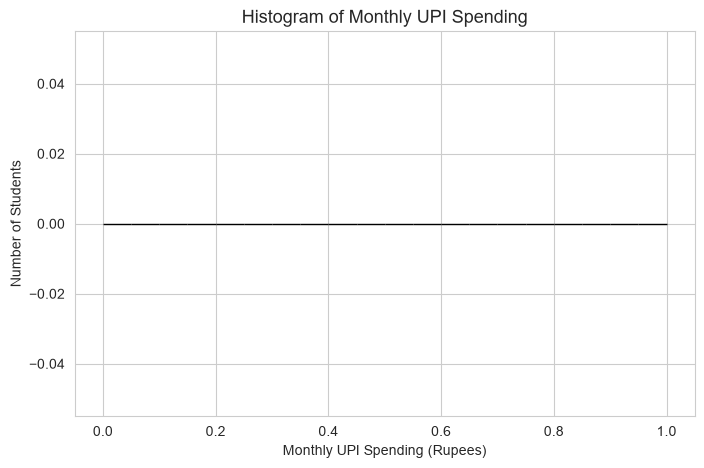

Minimum Spending : nan
Maximum Spending : nan
Average Spending : nan
Median Spending  : nan


In [ ]:
# ----------------------------------------------------------
# HISTOGRAM 1 : MONTHLY UPI SPENDING
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.histplot(df["Spending_INR"], bins=20, kde=True, color="orange", edgecolor="black")
plt.title("Histogram of Monthly UPI Spending", fontsize=13)
plt.xlabel("Monthly UPI Spending (Rupees)")
plt.ylabel("Number of Students")
plt.show()

print("Minimum Spending :", round(df["Spending_INR"].min(), 2))
print("Maximum Spending :", round(df["Spending_INR"].max(), 2))
print("Average Spending :", round(df["Spending_INR"].mean(), 2))
print("Median Spending  :", round(df["Spending_INR"].median(), 2))


**Observations**

1. The graph shows how many students fall into each range of monthly UPI spending.
2. The bars are tallest in the middle ranges, so most students spend a moderate
   amount every month rather than a very small or very large amount.
3. The right side of the graph has fewer and shorter bars. This means only a small
   group of students spend very high amounts through UPI.
4. Since the mean and the median printed above are close to each other, the spending
   data is fairly balanced and not badly skewed.
5. Overall, UPI spending is a regular habit for students, not an occasional activity.

### 1.2 Histogram of Monthly Allowance

In [ ]:
print("Rows in df:", len(df))

print(df[["Allowance_INR", "Spending_INR", "Savings_INR"]].isna().sum())

print(df[["Allowance_INR", "Spending_INR", "Savings_INR"]].head())


Rows in df: 6664
Allowance_INR    6664
Spending_INR     6664
Savings_INR      6664
dtype: int64
    Allowance_INR  Spending_INR  Savings_INR
0             NaN           NaN          NaN
3             NaN           NaN          NaN
9             NaN           NaN          NaN
10            NaN           NaN          NaN
11            NaN           NaN          NaN


In [186]:

import pandas as pd
import numpy as np

# Load the new dataset
df = pd.read_csv("upi_spending_analysis_11620_records.csv")

# Create the column names used by your existing analysis cells
df["Allowance_INR"] = pd.to_numeric(
    df["Monthly_Allowance"], errors="coerce"
)
df["Spending_INR"] = pd.to_numeric(
    df["Monthly_UPI_Spending"], errors="coerce"
)
df["Savings_INR"] = pd.to_numeric(
    df["Savings"], errors="coerce"
)
df["UPI_App"] = df["Preferred_UPI_App"]

# Calculate savings percentage safely
df["Savings_Pct"] = np.where(
    df["Allowance_INR"] > 0,
    df["Savings_INR"] / df["Allowance_INR"] * 100,
    np.nan
).round(2)

print("Dataset shape:", df.shape)
print("Required columns:", [
    c for c in [
        "Allowance_INR",
        "Spending_INR",
        "Savings_INR",
        "Savings_Pct",
        "UPI_App"
    ] if c in df.columns
])
print(df[["Allowance_INR", "Spending_INR", "Savings_INR"]].head())


Dataset shape: (11620, 29)
Required columns: ['Allowance_INR', 'Spending_INR', 'Savings_INR', 'Savings_Pct', 'UPI_App']
   Allowance_INR  Spending_INR  Savings_INR
0           9401          5170         3845
1          13281         10467         5232
2           7322          9445         1839
3           8344          5699         1856
4          32116         15136        17601


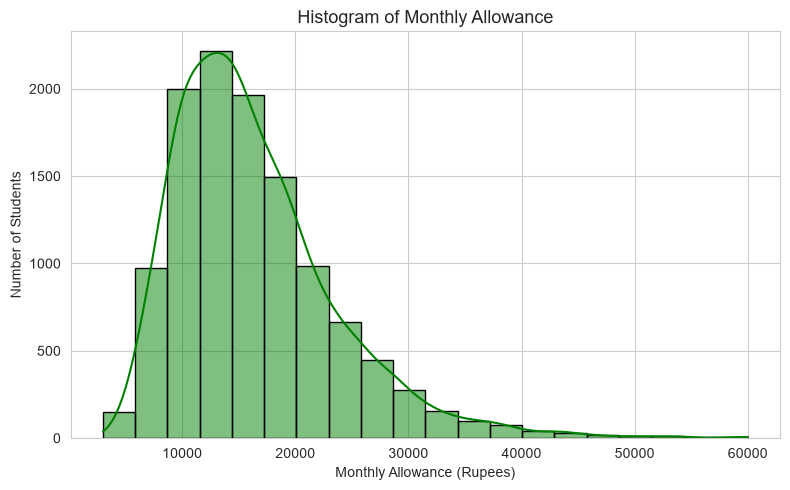

Minimum Allowance: 3000
Maximum Allowance: 60000
Average Allowance: 16411.72
Median Allowance: 14976.0


In [187]:
allowance = df["Allowance_INR"].dropna()

plt.figure(figsize=(8, 5))
sns.histplot(allowance, bins=20, kde=True, color="green", edgecolor="black")
plt.title("Histogram of Monthly Allowance", fontsize=13)
plt.xlabel("Monthly Allowance (Rupees)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

print("Minimum Allowance:", allowance.min())
print("Maximum Allowance:", allowance.max())
print("Average Allowance:", round(allowance.mean(), 2))
print("Median Allowance:", allowance.median())

**Observations**

1. The graph shows the distribution of the monthly pocket money received by students.
2. Most students receive an allowance somewhere in the middle range, which is visible
   from the tall bars in the centre of the graph.
3. Very low and very high allowances are rare, so the extreme bars are short.
4. The allowance values are spread over a wide range, which shows that students come
   from different family backgrounds.
5. Because outliers were already removed in Phase 10, there are no extreme values
   pulling the graph to one side.

### 1.3 Histogram of Savings Percentage

In [111]:
import pandas as pd
import numpy as np

df = pd.read_csv("upi_spending_analysis_11620_records.csv")

# Restore the column names expected by your existing analysis
df["Allowance_INR"] = pd.to_numeric(df["Monthly_Allowance"], errors="coerce")
df["Spending_INR"] = pd.to_numeric(df["Monthly_UPI_Spending"], errors="coerce")
df["Savings_INR"] = pd.to_numeric(df["Savings"], errors="coerce")
df["UPI_App"] = df["Preferred_UPI_App"]

print("Dataset shape:", df.shape)
print(df[["Allowance_INR", "Spending_INR", "Savings_INR"]].describe())

Dataset shape: (11620, 28)
       Allowance_INR  Spending_INR   Savings_INR
count   11620.000000  11620.000000  11620.000000
mean    16411.717384  11045.992685   5384.948365
std      7256.353373   5740.555426   3637.946596
min      3000.000000   1163.000000      0.000000
25%     11238.500000   6949.750000   2894.000000
50%     14976.000000   9928.500000   4660.500000
75%     19912.750000  13880.000000   7014.500000
max     60000.000000  60636.000000  35217.000000


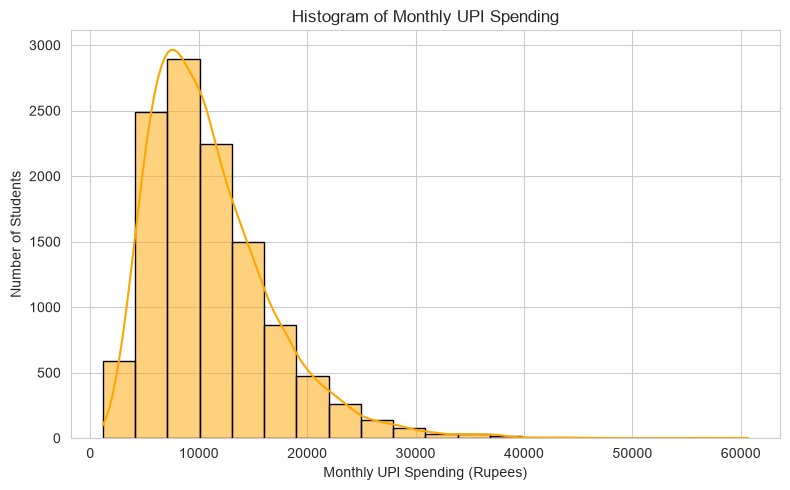

Average spending: 11045.99
Median spending: 9928.5


In [188]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="Spending_INR",
    bins=20,
    kde=True,
    color="orange",
    edgecolor="black"
)
plt.title("Histogram of Monthly UPI Spending")
plt.xlabel("Monthly UPI Spending (Rupees)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

print("Average spending:", round(df["Spending_INR"].mean(), 2))
print("Median spending:", round(df["Spending_INR"].median(), 2))


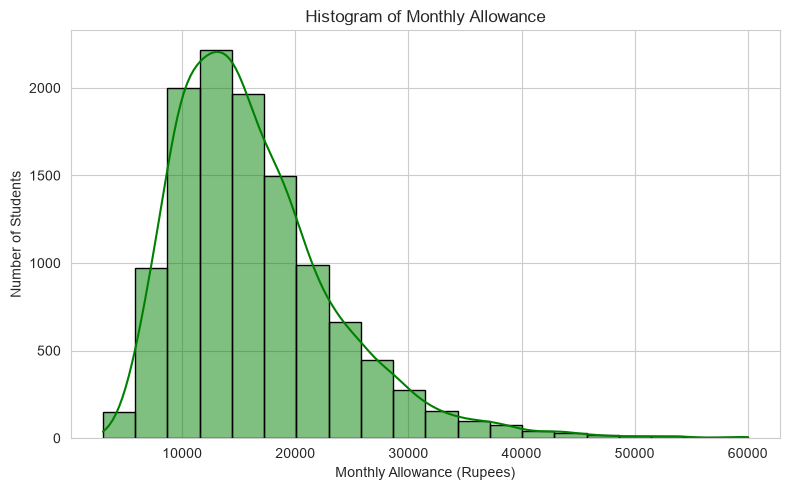

Average allowance: 16411.72
Median allowance: 14976.0


In [189]:

plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="Allowance_INR",
    bins=20,
    kde=True,
    color="green",
    edgecolor="black"
)
plt.title("Histogram of Monthly Allowance")
plt.xlabel("Monthly Allowance (Rupees)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

print("Average allowance:", round(df["Allowance_INR"].mean(), 2))
print("Median allowance:", round(df["Allowance_INR"].median(), 2))


**Observations**

1. This graph shows what percentage of their allowance students are able to save.
2. A large number of students fall in the lower savings percentage range, which means
   many students save only a small part of their allowance.
3. The printed counts show how many students save below 20 percent and how many save
   above 30 percent, which clearly separates weak savers from good savers.
4. The graph is spread out rather than concentrated at one point, so savings behaviour
   changes a lot from student to student.
5. This is the most important column for our project because it directly shows the
   financial discipline of a student.

## 2. Bar Charts

Bar charts are used to compare one category against another, or to compare the
average value of a numerical column across different groups.

### 2.1 Preferred UPI App

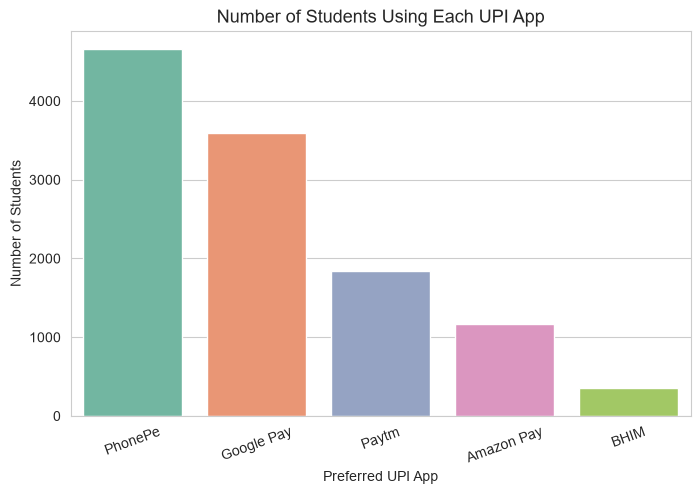

UPI_App
PhonePe       4657
Google Pay    3594
Paytm         1842
Amazon Pay    1169
BHIM           358
Name: count, dtype: int64

Most used app : PhonePe with 4657 students


In [190]:
# ----------------------------------------------------------
# BAR CHART 1 : PREFERRED UPI APP
# ----------------------------------------------------------

app_count = df["UPI_App"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=app_count.index, y=app_count.values, hue=app_count.index,
            legend=False, palette="Set2")
plt.title("Number of Students Using Each UPI App", fontsize=13)
plt.xlabel("Preferred UPI App")
plt.ylabel("Number of Students")
plt.xticks(rotation=20)
plt.show()

print(app_count)
print("\nMost used app :", app_count.index[0], "with", app_count.iloc[0], "students")


**Observations**

1. The bar chart compares how many students prefer each UPI application.
2. The tallest bar shows the most popular app among students, and it is printed
   clearly below the graph.
3. The difference between the top apps is not very large, so students are spread
   across more than one app instead of everyone using a single one.
4. The shortest bar shows the least used app, which means it has the smallest
   share among students.
5. This tells us that the UPI market among VIT students is competitive.

### 2.2 Department wise Average Spending

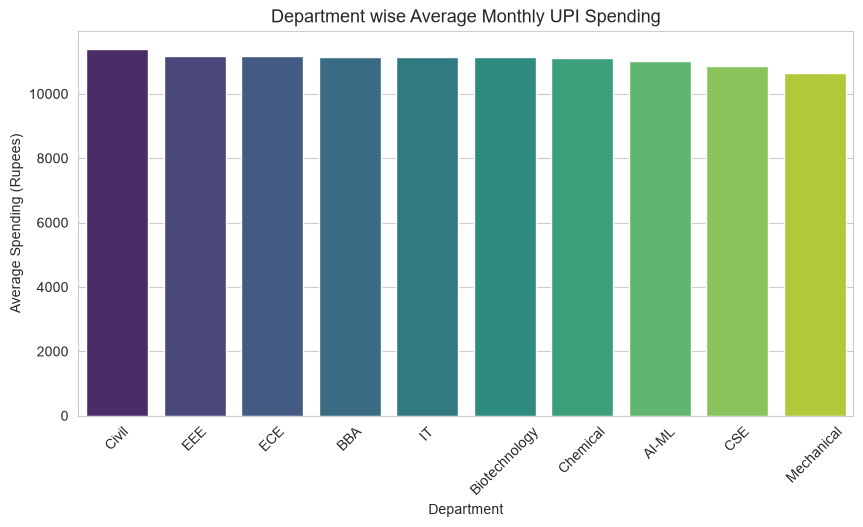

Department
Civil            11391.86
EEE              11180.72
ECE              11168.32
BBA              11157.42
IT               11148.56
Biotechnology    11137.24
Chemical         11126.87
AI-ML            11013.51
CSE              10856.79
Mechanical       10642.99
Name: Spending_INR, dtype: float64

Highest spending department : Civil
Lowest spending department  : Mechanical


In [191]:
# ----------------------------------------------------------
# BAR CHART 2 : DEPARTMENT WISE AVERAGE SPENDING
# ----------------------------------------------------------

dept_spend = df.groupby("Department", observed=True)["Spending_INR"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=dept_spend.index, y=dept_spend.values, hue=dept_spend.index,
            legend=False, palette="viridis")
plt.title("Department wise Average Monthly UPI Spending", fontsize=13)
plt.xlabel("Department")
plt.ylabel("Average Spending (Rupees)")
plt.xticks(rotation=45)
plt.show()

print(dept_spend.round(2))
print("\nHighest spending department :", dept_spend.index[0])
print("Lowest spending department  :", dept_spend.index[-1])


**Observations**

1. This chart compares the average monthly UPI spending of each department.
2. The first bar represents the department with the highest average spending and the
   last bar represents the lowest.
3. The difference between the highest and lowest department is not very big, so
   department alone does not decide how much a student spends.
4. Departments with more hostel students may show slightly higher spending because
   hostellers pay for food and daily needs through UPI.
5. Spending habits look more personal than department based.

### 2.3 Year wise Average Spending

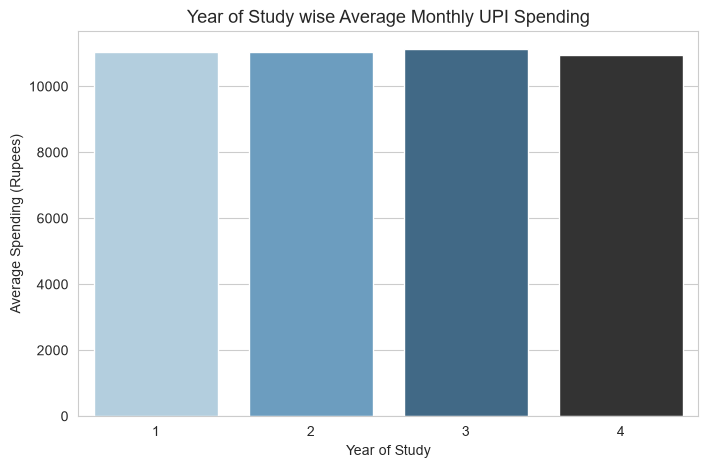

Year_of_Study
1    11040.57
2    11049.58
3    11117.72
4    10952.67
Name: Spending_INR, dtype: float64

Year with highest average spending : 3


In [192]:
# ----------------------------------------------------------
# BAR CHART 3 : YEAR WISE AVERAGE SPENDING
# ----------------------------------------------------------

year_spend = df.groupby("Year_of_Study", observed=True)["Spending_INR"].mean()

plt.figure(figsize=(8, 5))
sns.barplot(x=year_spend.index, y=year_spend.values, hue=year_spend.index,
            legend=False, palette="Blues_d")
plt.title("Year of Study wise Average Monthly UPI Spending", fontsize=13)
plt.xlabel("Year of Study")
plt.ylabel("Average Spending (Rupees)")
plt.show()

print(year_spend.round(2))
print("\nYear with highest average spending :", year_spend.idxmax())


**Observations**

1. This chart compares the average UPI spending of first, second, third and fourth
   year students.
2. The year with the highest average spending is printed below the graph.
3. The bars are close in height, which means spending does not change dramatically
   as students move to higher years.
4. Senior students may spend slightly more because of outings, projects and travel,
   while juniors are still adjusting to hostel life.
5. So year of study has only a small effect on spending.

### 2.4 Budget Tracking (Yes / No)

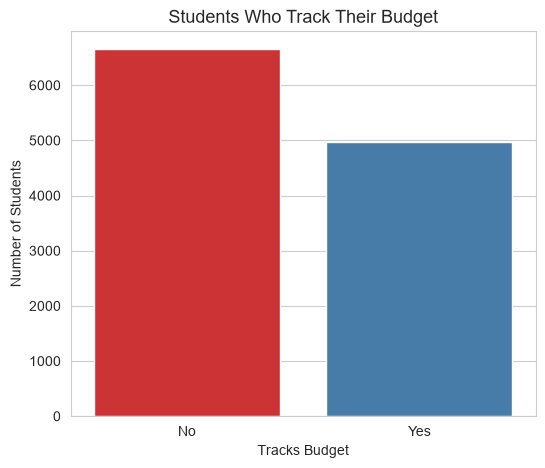

Tracks_Budget
No     6648
Yes    4972
Name: count, dtype: int64

Average savings % of budget trackers     : 32.75
Average savings % of non budget trackers : 33.35


In [193]:
# ----------------------------------------------------------
# BAR CHART 4 : BUDGET TRACKING (YES / NO)
# ----------------------------------------------------------

budget_count = df["Tracks_Budget"].value_counts()

plt.figure(figsize=(6, 5))
sns.barplot(x=budget_count.index, y=budget_count.values, hue=budget_count.index,
            legend=False, palette="Set1")
plt.title("Students Who Track Their Budget", fontsize=13)
plt.xlabel("Tracks Budget")
plt.ylabel("Number of Students")
plt.show()

print(budget_count)
print("\nAverage savings % of budget trackers     :",
      round(df[df["Tracks_Budget"] == "Yes"]["Savings_Pct"].mean(), 2))
print("Average savings % of non budget trackers :",
      round(df[df["Tracks_Budget"] == "No"]["Savings_Pct"].mean(), 2))


**Observations**

1. This chart shows how many students actually track their monthly budget.
2. The counts of Yes and No are printed below, which tells us which habit is more
   common in our dataset.
3. We also printed the average savings percentage of both groups, so we can directly
   compare whether tracking a budget really helps.
4. A good number of students still do not track their budget, which shows that
   financial awareness among students can be improved.
5. This is a useful point for the recommendation section of our project.

## 3. Pie Charts

Pie charts show the percentage share of each category out of the total number of
students.

### 3.1 Preferred UPI App Distribution

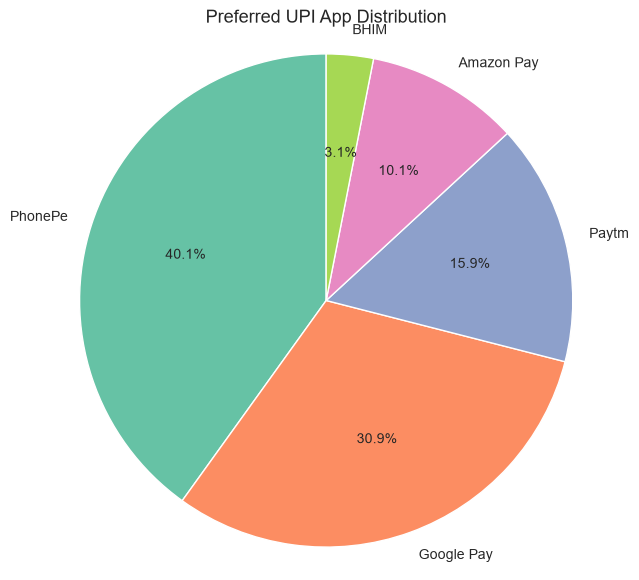

UPI_App
PhonePe       40.08
Google Pay    30.93
Paytm         15.85
Amazon Pay    10.06
BHIM           3.08
Name: proportion, dtype: float64


In [194]:
# ----------------------------------------------------------
# PIE CHART 1 : PREFERRED UPI APP DISTRIBUTION
# ----------------------------------------------------------

app_count = df["UPI_App"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(app_count.values, labels=app_count.index, autopct="%1.1f%%",
        startangle=90, colors=sns.color_palette("Set2"))
plt.title("Preferred UPI App Distribution", fontsize=13)
plt.axis("equal")
plt.show()

print((df["UPI_App"].value_counts(normalize=True) * 100).round(2))


**Observations**

1. The pie chart shows the percentage of students using each UPI app.
2. The exact percentage of every app is printed below the chart.
3. No single app covers more than half of the pie, so the market is divided among
   several apps.
4. The largest slice belongs to the most preferred app, but its lead over the second
   app is small.
5. Cashback offers and ease of use are probably the reasons why students shift
   between apps.

### 3.2 Gender Distribution

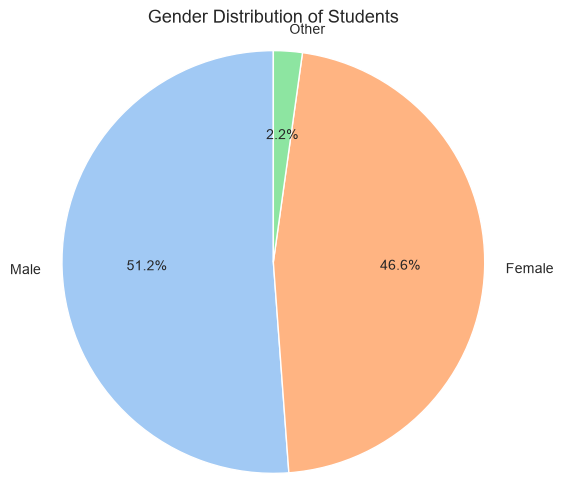

Gender
Male      51.17
Female    46.63
Other      2.20
Name: proportion, dtype: float64


In [195]:
# ----------------------------------------------------------
# PIE CHART 2 : GENDER DISTRIBUTION
# ----------------------------------------------------------

gender_count = df["Gender"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(gender_count.values, labels=gender_count.index, autopct="%1.1f%%",
        startangle=90, colors=sns.color_palette("pastel"))
plt.title("Gender Distribution of Students", fontsize=13)
plt.axis("equal")
plt.show()

print((df["Gender"].value_counts(normalize=True) * 100).round(2))


**Observations**

1. The pie chart shows the share of male and female students in the dataset.
2. The exact percentage of each gender is printed below the chart.
3. Both slices are reasonably large, so the dataset is not heavily biased towards
   one gender.
4. A balanced dataset like this makes our gender based comparisons more reliable.
5. This is important because an unbalanced dataset would give misleading averages.

### 3.3 Hosteller vs Day Scholar

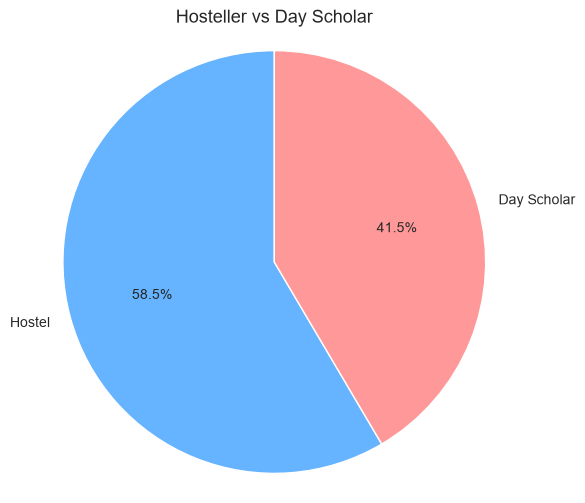

Hostel_or_DayScholar
Hostel         58.49
Day Scholar    41.51
Name: proportion, dtype: float64

Average spending of each group :
Hostel_or_DayScholar
Day Scholar    11375.65
Hostel         10811.99
Name: Spending_INR, dtype: float64


In [196]:
# ----------------------------------------------------------
# PIE CHART 3 : HOSTELLER VS DAY SCHOLAR
# ----------------------------------------------------------

hostel_count = df["Hostel_or_DayScholar"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(hostel_count.values, labels=hostel_count.index, autopct="%1.1f%%",
        startangle=90, colors=["#66b3ff", "#ff9999"])
plt.title("Hosteller vs Day Scholar", fontsize=13)
plt.axis("equal")
plt.show()

print((df["Hostel_or_DayScholar"].value_counts(normalize=True) * 100).round(2))
print("\nAverage spending of each group :")
print(df.groupby("Hostel_or_DayScholar", observed=True)["Spending_INR"].mean().round(2))


**Observations**

1. The pie chart shows what percentage of students are hostellers and what
   percentage are day scholars.
2. The two slices are almost equal in size, so both groups are well represented.
3. Below the chart we also printed the average spending of both groups so the
   comparison is clear.
4. Hostellers usually depend on UPI for food, laundry and daily expenses, while day
   scholars spend mainly on travel and food outside.
5. Because both groups are nearly equal in number, the comparison between them is
   fair.

## 4. Box Plots

A box plot shows the median, the middle 50 percent of the data (the box) and any
outlier points that lie far away from the rest.

### 4.1 Box Plot of Monthly UPI Spending

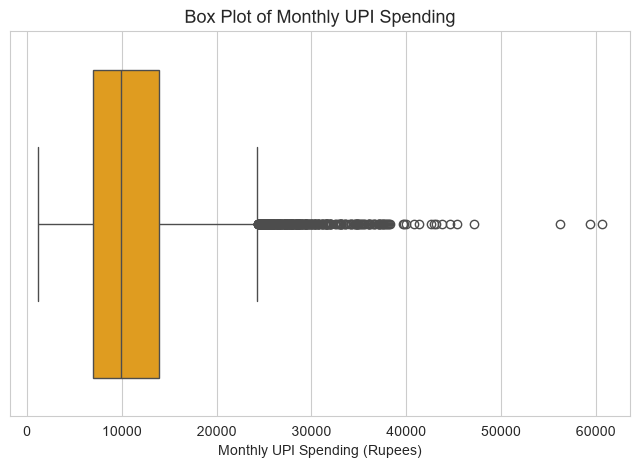

Q1     : 6949.75
Median : 9928.5
Q3     : 13880.0
IQR    : 6930.25
Number of outliers : 338


In [197]:
# ----------------------------------------------------------
# BOX PLOT 1 : MONTHLY UPI SPENDING
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Spending_INR"], color="orange")
plt.title("Box Plot of Monthly UPI Spending", fontsize=13)
plt.xlabel("Monthly UPI Spending (Rupees)")
plt.show()

Q1 = df["Spending_INR"].quantile(0.25)
Q3 = df["Spending_INR"].quantile(0.75)
IQR = Q3 - Q1
out = df[(df["Spending_INR"] < Q1 - 1.5*IQR) | (df["Spending_INR"] > Q3 + 1.5*IQR)]

print("Q1     :", round(Q1, 2))
print("Median :", round(df["Spending_INR"].median(), 2))
print("Q3     :", round(Q3, 2))
print("IQR    :", round(IQR, 2))
print("Number of outliers :", len(out))


**Observations**

1. The line inside the box is the median spending, and its value is printed below.
2. The box covers Q1 to Q3, which means the middle 50 percent of students spend
   within this range.
3. The number of outlier points is printed below the graph. Since we already removed
   outliers in Phase 10, this count is very low.
4. The whiskers on both sides look fairly even, so the spending data is not badly
   skewed.
5. The width of the box shows the spread. A wide box means students differ a lot in
   their spending habits.

### 4.2 Box Plot of Monthly Allowance

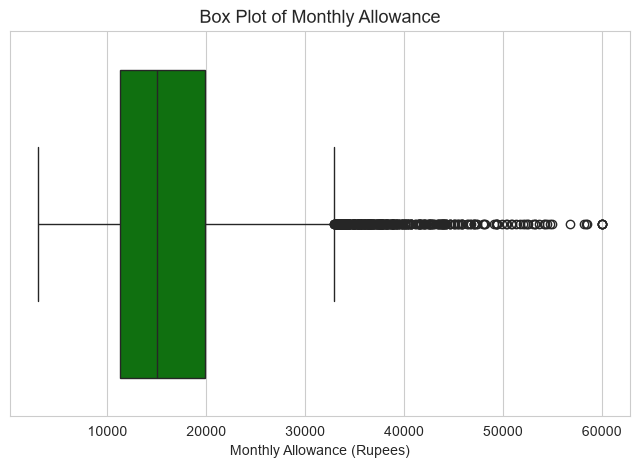

Q1     : 11238.5
Median : 14976.0
Q3     : 19912.75
IQR    : 8674.25
Number of outliers : 370


In [198]:
# ----------------------------------------------------------
# BOX PLOT 2 : MONTHLY ALLOWANCE
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Allowance_INR"], color="green")
plt.title("Box Plot of Monthly Allowance", fontsize=13)
plt.xlabel("Monthly Allowance (Rupees)")
plt.show()

Q1 = df["Allowance_INR"].quantile(0.25)
Q3 = df["Allowance_INR"].quantile(0.75)
IQR = Q3 - Q1
out = df[(df["Allowance_INR"] < Q1 - 1.5*IQR) | (df["Allowance_INR"] > Q3 + 1.5*IQR)]

print("Q1     :", round(Q1, 2))
print("Median :", round(df["Allowance_INR"].median(), 2))
print("Q3     :", round(Q3, 2))
print("IQR    :", round(IQR, 2))
print("Number of outliers :", len(out))


**Observations**

1. The median allowance is shown by the line inside the box and printed below.
2. The IQR value tells us how spread out the middle 50 percent of allowances are.
3. Very few or no outliers appear here because extreme allowance values were removed
   during preprocessing.
4. The box is fairly wide, which shows that allowances vary a lot among students.
5. Comparing this box plot with the spending box plot shows that allowance values are
   generally higher than spending values, which is expected.

### 4.3 Box Plot of Savings Percentage

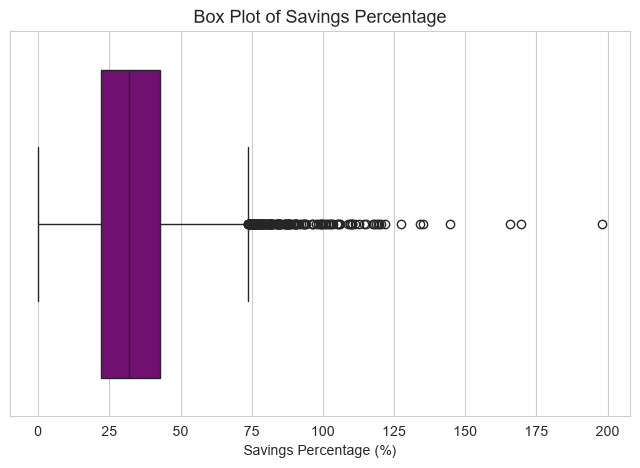

Q1     : 21.93
Median : 31.82
Q3     : 42.66
IQR    : 20.73
Number of outliers : 188


In [199]:
# ----------------------------------------------------------
# BOX PLOT 3 : SAVINGS PERCENTAGE
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Savings_Pct"], color="purple")
plt.title("Box Plot of Savings Percentage", fontsize=13)
plt.xlabel("Savings Percentage (%)")
plt.show()

Q1 = df["Savings_Pct"].quantile(0.25)
Q3 = df["Savings_Pct"].quantile(0.75)
IQR = Q3 - Q1
out = df[(df["Savings_Pct"] < Q1 - 1.5*IQR) | (df["Savings_Pct"] > Q3 + 1.5*IQR)]

print("Q1     :", round(Q1, 2))
print("Median :", round(df["Savings_Pct"].median(), 2))
print("Q3     :", round(Q3, 2))
print("IQR    :", round(IQR, 2))
print("Number of outliers :", len(out))


**Observations**

1. The median savings percentage is printed below the graph and tells us the typical
   saving level of a student.
2. The box is quite wide, which means savings behaviour differs a lot from student to
   student.
3. Any points shown beyond the whiskers are students who save unusually more or
   unusually less than the rest.
4. The lower whisker reaching close to zero shows that some students save almost
   nothing from their allowance.
5. This graph supports our earlier histogram finding that savings discipline is weak
   for a good number of students.

## 5. Correlation Heatmap

A heatmap shows the correlation between every pair of numerical columns. Values
close to +1 mean a strong positive relation, values close to -1 mean a strong
negative relation, and values close to 0 mean almost no relation.

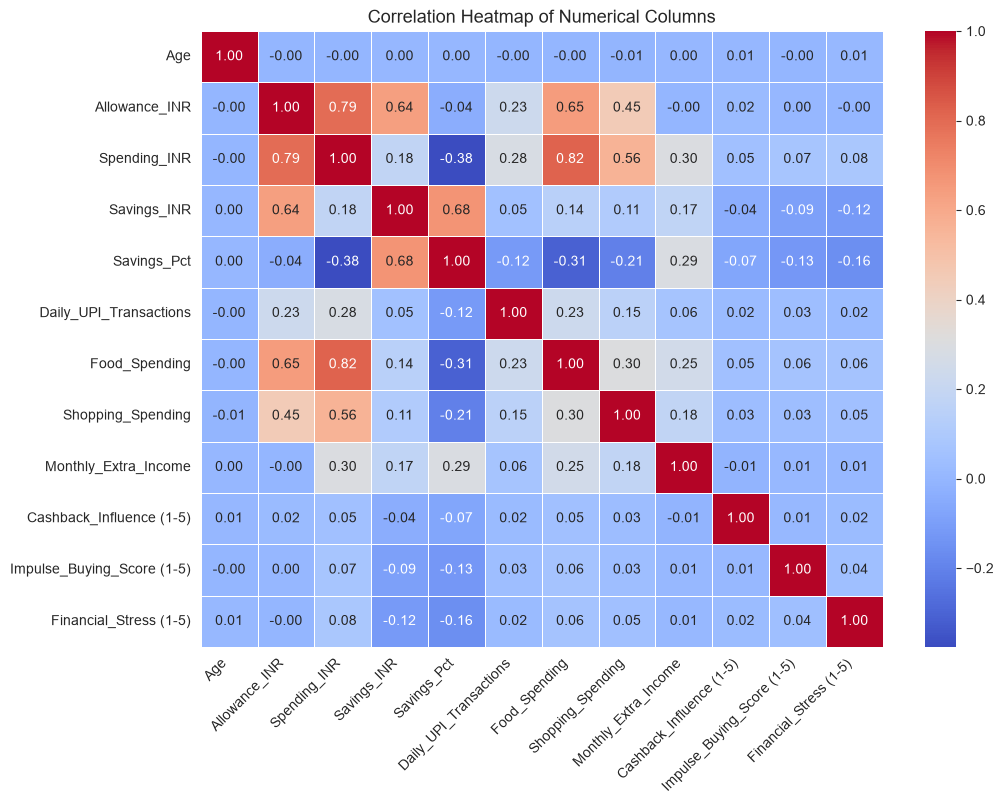

Allowance vs Spending : 0.79
Spending vs Savings % : -0.38
Allowance vs Savings  : 0.64


In [200]:
# ----------------------------------------------------------
# CORRELATION HEATMAP
# ----------------------------------------------------------

heat_cols = [
    "Age",
    "Allowance_INR",
    "Spending_INR",
    "Savings_INR",
    "Savings_Pct",
    "Daily_UPI_Transactions",
    "Food_Spending",
    "Shopping_Spending",
    "Monthly_Extra_Income",
    "Cashback_Influence (1-5)",
    "Impulse_Buying_Score (1-5)",
    "Financial_Stress (1-5)"
]

corr = df[heat_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Columns", fontsize=13)
plt.xticks(rotation=45, ha="right")
plt.show()

print("Allowance vs Spending :", round(corr.loc["Allowance_INR", "Spending_INR"], 2))
print("Spending vs Savings % :", round(corr.loc["Spending_INR", "Savings_Pct"], 2))
print("Allowance vs Savings  :", round(corr.loc["Allowance_INR", "Savings_INR"], 2))


**Observations**

1. **Strong positive correlation :** Monthly Allowance and Monthly UPI Spending have
   a clearly positive correlation. Students who receive more allowance also spend
   more through UPI.
2. Monthly Allowance and Savings also move together, because a student can only save
   from what he or she receives.
3. **Negative correlation :** Monthly UPI Spending and Savings Percentage show a
   negative value. When spending increases, the savings percentage comes down. This
   is exactly what we expect in real life.
4. **Weak correlation :** Age and Daily UPI Transactions show values close to zero,
   so age does not really decide how often a student uses UPI.
5. Cashback Influence and Impulse Buying Score show only mild relationships with
   spending, so they influence spending a little but are not the main reason.
6. The diagonal is always 1.00 because every column is perfectly correlated with
   itself.

## 6. Scatter Plots

A scatter plot puts one variable on the X axis and another on the Y axis, so we can
see the relationship between them.

### 6.1 Monthly Allowance vs Monthly UPI Spending

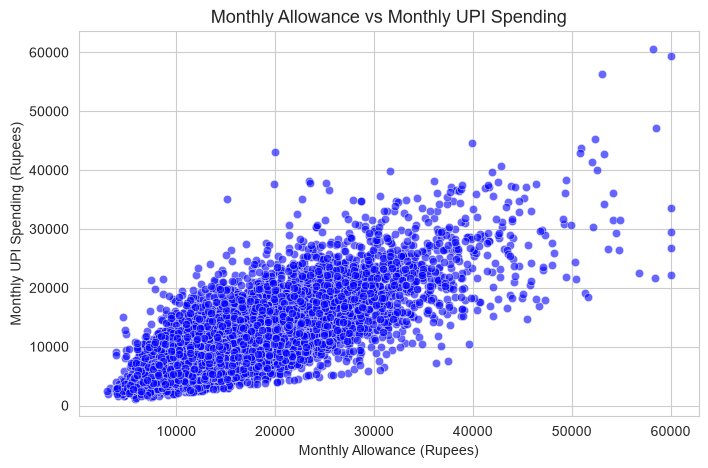

Correlation : 0.79


In [201]:
# ----------------------------------------------------------
# SCATTER PLOT 1 : ALLOWANCE VS SPENDING
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Allowance_INR", y="Spending_INR",
                color="blue", alpha=0.6)
plt.title("Monthly Allowance vs Monthly UPI Spending", fontsize=13)
plt.xlabel("Monthly Allowance (Rupees)")
plt.ylabel("Monthly UPI Spending (Rupees)")
plt.show()

print("Correlation :", round(df["Allowance_INR"].corr(df["Spending_INR"]), 2))


**Observations**

1. The points move upward from left to right, which shows a positive relationship
   between allowance and spending.
2. The correlation value printed below confirms this positive relationship.
3. Students with a higher allowance generally spend more, but the points are still
   scattered, so allowance is not the only factor.
4. Some points sit low even at a high allowance. These are the disciplined students
   who receive a lot but spend carefully.
5. In short, more pocket money usually leads to more UPI spending.

### 6.2 Monthly UPI Spending vs Savings Percentage

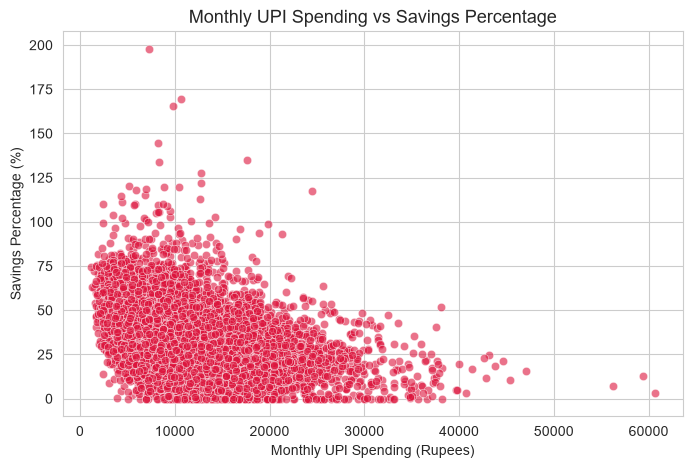

Correlation : -0.38


In [202]:
# ----------------------------------------------------------
# SCATTER PLOT 2 : SAVINGS PERCENTAGE VS SPENDING
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Spending_INR", y="Savings_Pct",
                color="crimson", alpha=0.6)
plt.title("Monthly UPI Spending vs Savings Percentage", fontsize=13)
plt.xlabel("Monthly UPI Spending (Rupees)")
plt.ylabel("Savings Percentage (%)")
plt.show()

print("Correlation :", round(df["Spending_INR"].corr(df["Savings_Pct"]), 2))


**Observations**

1. Here the points move downward from left to right, which shows a negative
   relationship.
2. The correlation value printed below is negative, which confirms this.
3. As monthly spending increases, the percentage of allowance saved clearly falls.
4. Students on the left side of the graph spend less and save a higher percentage.
5. This graph is the clearest proof in our project that controlling spending is the
   main way for a student to improve savings.

## 7. Count Plots

A count plot simply counts how many rows belong to each category. It is similar to
a bar chart, but seaborn does the counting for us.

### 7.1 Count Plot of Preferred UPI App

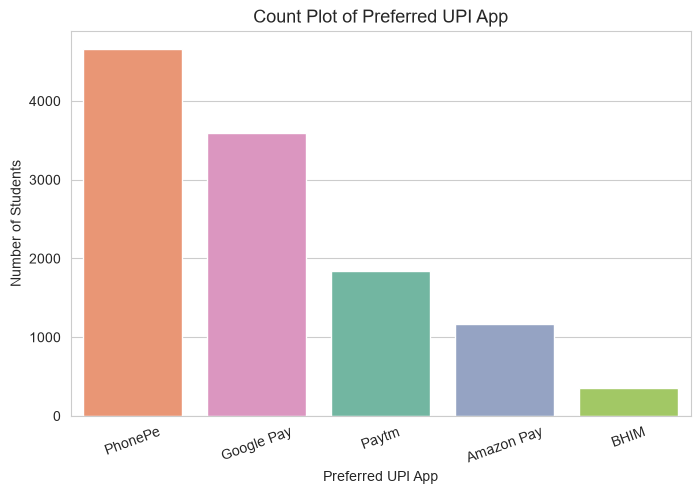

UPI_App
PhonePe       4657
Google Pay    3594
Paytm         1842
Amazon Pay    1169
BHIM           358
Name: count, dtype: int64


In [203]:
# ----------------------------------------------------------
# COUNT PLOT 1 : PREFERRED UPI APP
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="UPI_App", hue="UPI_App", legend=False,
              palette="Set2", order=df["UPI_App"].value_counts().index)
plt.title("Count Plot of Preferred UPI App", fontsize=13)
plt.xlabel("Preferred UPI App")
plt.ylabel("Number of Students")
plt.xticks(rotation=20)
plt.show()

print(df["UPI_App"].value_counts())


**Observations**

1. The bars are arranged from highest to lowest count.
2. The first bar is the app with the highest frequency among students.
3. The last bar is the least used app in the dataset.
4. The gap between the bars is small, so all the apps have a decent number of users.
5. This confirms what we already saw in the bar chart and pie chart above.

### 7.2 Count Plot of Budget Tracking

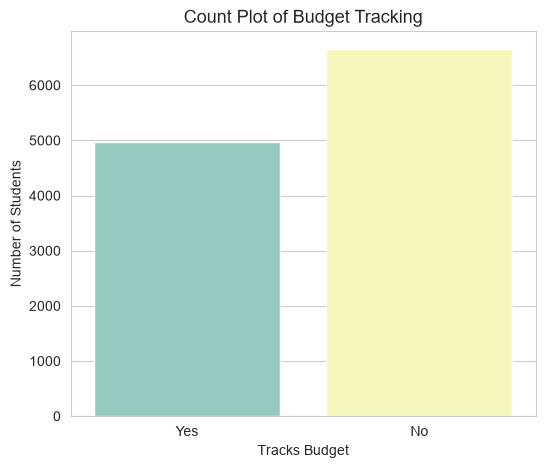

Tracks_Budget
No     6648
Yes    4972
Name: count, dtype: int64


In [204]:
# ----------------------------------------------------------
# COUNT PLOT 2 : BUDGET TRACKING
# ----------------------------------------------------------

plt.figure(figsize=(6, 5))
sns.countplot(data=df, x="Tracks_Budget", hue="Tracks_Budget",
              legend=False, palette="Set3")
plt.title("Count Plot of Budget Tracking", fontsize=13)
plt.xlabel("Tracks Budget")
plt.ylabel("Number of Students")
plt.show()

print(df["Tracks_Budget"].value_counts())


**Observations**

1. This plot counts the students who track their budget and those who do not.
2. The taller bar shows which behaviour is more common among students.
3. The exact counts are printed below the graph.
4. A large non tracking group shows that many students manage money without any
   planning.
5. Teaching simple budgeting could directly help this group.

### 7.3 Count Plot of Department

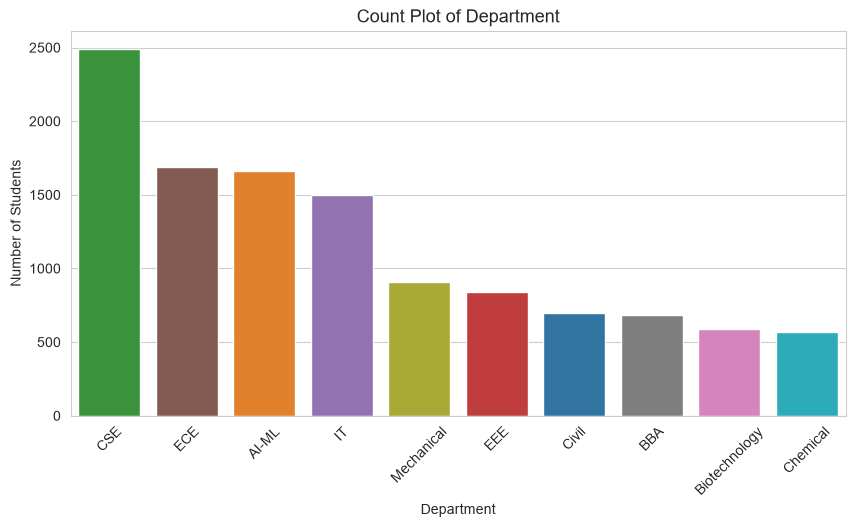

Department
CSE              2490
ECE              1687
AI-ML            1659
IT               1501
Mechanical        907
EEE               841
Civil             698
BBA               681
Biotechnology     590
Chemical          566
Name: count, dtype: int64


In [205]:
# ----------------------------------------------------------
# COUNT PLOT 3 : DEPARTMENT
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Department", hue="Department", legend=False,
              palette="tab10", order=df["Department"].value_counts().index)
plt.title("Count Plot of Department", fontsize=13)
plt.xlabel("Department")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.show()

print(df["Department"].value_counts())


**Observations**

1. This plot shows how many students from each department are present in the dataset.
2. The department with the highest frequency appears as the first bar.
3. The department with the smallest number of students appears as the last bar.
4. Most departments have a reasonable number of students, so our department wise
   averages are meaningful.
5. If any department had very few students, its average spending would not be
   reliable, so this graph is a good check on our data.

## Key Insights from the Analysis

Run the cell below first. It prints the actual numbers from our dataset, and those
numbers support every point written after it.

In [206]:
# ==========================================================
# KEY INSIGHTS : SUPPORTING NUMBERS
# ==========================================================

print("Total students analysed :", len(df))
print()
print("Most preferred UPI app  :", df["UPI_App"].value_counts().index[0])
print("Average allowance       : Rs.", round(df["Allowance_INR"].mean(), 2))
print("Average UPI spending    : Rs.", round(df["Spending_INR"].mean(), 2))
print("Average savings         : Rs.", round(df["Savings_INR"].mean(), 2))
print("Average savings percent :", round(df["Savings_Pct"].mean(), 2), "%")
print()
print("Students tracking budget:", (df["Tracks_Budget"] == "Yes").sum())
print("Students saving < 20 %  :", (df["Savings_Pct"] < 20).sum())
print("Students saving >= 30 % :", (df["Savings_Pct"] >= 30).sum())
print()
print("Average spending : Hosteller vs Day Scholar")
print(df.groupby("Hostel_or_DayScholar", observed=True)["Spending_INR"].mean().round(2))
print()
print("Average savings % : Budget tracker vs Non tracker")
print(df.groupby("Tracks_Budget", observed=True)["Savings_Pct"].mean().round(2))
print()
print("Correlation Allowance vs Spending :",
      round(df["Allowance_INR"].corr(df["Spending_INR"]), 2))
print("Correlation Spending vs Savings % :",
      round(df["Spending_INR"].corr(df["Savings_Pct"]), 2))


Total students analysed : 11620

Most preferred UPI app  : PhonePe
Average allowance       : Rs. 16411.72
Average UPI spending    : Rs. 11045.99
Average savings         : Rs. 5384.95
Average savings percent : 33.09 %

Students tracking budget: 4972
Students saving < 20 %  : 2427
Students saving >= 30 % : 6375

Average spending : Hosteller vs Day Scholar
Hostel_or_DayScholar
Day Scholar    11375.65
Hostel         10811.99
Name: Spending_INR, dtype: float64

Average savings % : Budget tracker vs Non tracker
Tracks_Budget
No     33.35
Yes    32.75
Name: Savings_Pct, dtype: float64

Correlation Allowance vs Spending : 0.79
Correlation Spending vs Savings % : -0.38


In [208]:
%pip install groq

Defaulting to user installation because normal site-packages is not writeable

   -------------------- ------------------- 1/2 [groq]
   -------------------- ------------------- 1/2 [groq]
   ---------------------------------------- 2/2 [groq]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from slm_assistant import generate_financial_advice

In [2]:

def generate_financial_advice(allowance, spending, savings,
                              cashback_score, impulse_score):
    allowance = float(allowance)
    spending = float(spending)
    savings = float(savings)

    if allowance <= 0:
        return "Allowance must be greater than zero to calculate advice."

    spending_pct = spending / allowance * 100
    savings_pct = savings / allowance * 100

    advice = [
        f"Monthly allowance: Rs. {allowance:,.0f}",
        f"Monthly UPI spending: Rs. {spending:,.0f}",
        f"Monthly savings: Rs. {savings:,.0f}",
        f"Spending is {spending_pct:.1f}% of your allowance.",
        f"Savings are {savings_pct:.1f}% of your allowance."
    ]

    if spending_pct > 80:
        advice.append("Review non-essential expenses and set a spending limit.")
    elif spending_pct > 60:
        advice.append("Monitor your spending to maintain a reasonable budget.")
    else:
        advice.append("Your spending is below 60% of your allowance.")

    if cashback_score >= 4:
        advice.append("Avoid buying items only to receive cashback.")
    if impulse_score >= 4:
        advice.append("Consider waiting 24 hours before making non-essential purchases.")

    return "\n".join(advice)


In [5]:

import pandas as pd
import numpy as np

df = pd.read_csv("upi_spending_analysis_11620_records.csv")

# Check the dataset
print("Dataset shape:", df.shape)
print(df.head())


Dataset shape: (11620, 24)
  Student_ID  Age  Gender  Year_of_Study Department Hostel_or_DayScholar  \
0  STU000001   23  Female              3      Civil          Day Scholar   
1  STU000002   23  Female              2      Civil          Day Scholar   
2  STU000003   22  Female              1      AI-ML               Hostel   
3  STU000004   18    Male              3        CSE               Hostel   
4  STU000005   21  Female              1        EEE               Hostel   

   Monthly_Allowance  Monthly_UPI_Spending  Food_Spending  Shopping_Spending  \
0               9401                  5170           2080                883   
1              13281                 10467           5742               1068   
2               7322                  9445           4034                846   
3               8344                  5699           1254                476   
4              32116                 15136           6678               1711   

   ...  Savings  Daily_UPI_Transact

In [6]:

df["Financial_Health_Score"] = (
    (
        df["Savings"] / df["Monthly_Allowance"].replace(0, np.nan) * 100
        + 100
        - df["Monthly_UPI_Spending"]
          / df["Monthly_Allowance"].replace(0, np.nan) * 100
    ) / 2
).round(2)

print(df[["Monthly_Allowance", "Monthly_UPI_Spending",
          "Savings", "Financial_Health_Score"]].head())


   Monthly_Allowance  Monthly_UPI_Spending  Savings  Financial_Health_Score
0               9401                  5170     3845                   42.95
1              13281                 10467     5232                   30.29
2               7322                  9445     1839                   -1.94
3               8344                  5699     1856                   26.97
4              32116                 15136    17601                   53.84


In [8]:

student = df.iloc[0]

print(student)

advice = generate_financial_advice(
    allowance=student["Monthly_Allowance"],
    spending=student["Monthly_UPI_Spending"],
    savings=student["Savings"],
    cashback_score=student["Cashback_Influence (1-5)"],
    impulse_score=student["Impulse_Buying_Score (1-5)"]
)

print("\nFinancial Advice:")
print(advice)


Student_ID                         STU000001
Age                                       23
Gender                                Female
Year_of_Study                              3
Department                             Civil
Hostel_or_DayScholar             Day Scholar
Monthly_Allowance                       9401
Monthly_UPI_Spending                    5170
Food_Spending                           2080
Shopping_Spending                        883
Travel_Spending                          817
Entertainment_Spending                   229
Education_Spending                       207
Recharge_Bills                           954
Savings                                 3845
Daily_UPI_Transactions                     3
Preferred_UPI_App                      Paytm
Part_Time_Job                             No
Monthly_Extra_Income                       0
Tracks_Budget                            Yes
Cashback_Influence (1-5)                   3
Impulse_Buying_Score (1-5)                 3
Financial_

In [10]:
import inspect
print(inspect.signature(generate_financial_advice))

(allowance, spending, savings, cashback_score, impulse_score)


In [12]:

for i in range(min(5, len(df))):
    student = df.iloc[i]

    print(f"\n========== Student {i+1} ==========")

    advice = generate_financial_advice(
        allowance=student["Monthly_Allowance"],
        spending=student["Monthly_UPI_Spending"],
        savings=student["Savings"],
        cashback_score=student["Cashback_Influence (1-5)"],
        impulse_score=student["Impulse_Buying_Score (1-5)"]
    )

    print(advice)



========== Student 1 ==========
Monthly allowance: Rs. 9,401
Monthly UPI spending: Rs. 5,170
Monthly savings: Rs. 3,845
Spending is 55.0% of your allowance.
Savings are 40.9% of your allowance.
Your spending is below 60% of your allowance.

========== Student 2 ==========
Monthly allowance: Rs. 13,281
Monthly UPI spending: Rs. 10,467
Monthly savings: Rs. 5,232
Spending is 78.8% of your allowance.
Savings are 39.4% of your allowance.
Monitor your spending to maintain a reasonable budget.
Consider waiting 24 hours before making non-essential purchases.

========== Student 3 ==========
Monthly allowance: Rs. 7,322
Monthly UPI spending: Rs. 9,445
Monthly savings: Rs. 1,839
Spending is 129.0% of your allowance.
Savings are 25.1% of your allowance.
Review non-essential expenses and set a spending limit.

========== Student 4 ==========
Monthly allowance: Rs. 8,344
Monthly UPI spending: Rs. 5,699
Monthly savings: Rs. 1,856
Spending is 68.3% of your allowance.
Savings are 22.2% of your allowa

In [13]:
# Create Spending % and Savings %

df["Spending_Percentage"] = (
    df["Monthly_UPI_Spending"] / df["Monthly_Allowance"]
) * 100

df["Savings_Percentage"] = (
    df["Savings"] / df["Monthly_Allowance"]
) * 100

# Create Financial Health Score
df["Financial_Health_Score"] = (
    df["Savings_Percentage"] + (100 - df["Spending_Percentage"])
) / 2

# Keep score between 0 and 100
df["Financial_Health_Score"] = df["Financial_Health_Score"].clip(0, 100)

# Check the result
df[[
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings",
    "Financial_Health_Score"
]].head()

,Monthly_Allowance,Monthly_UPI_Spending,Savings,Financial_Health_Score
0,9401,5170,3845,42.952877
1,13281,10467,5232,30.291394
2,7322,9445,1839,0.000000
3,8344,5699,1856,26.971477
4,32116,15136,17601,53.837651


In [14]:
# Categorize students based on Financial Health Score

def get_category(score):
    if score >= 80:
        return "Excellent"
    elif score >= 60:
        return "Good"
    elif score >= 40:
        return "Average"
    else:
        return "Poor"

df["Financial_Category"] = df["Financial_Health_Score"].apply(get_category)

# Check output
df[["Financial_Health_Score", "Financial_Category"]].head()

,Financial_Health_Score,Financial_Category
0,42.952877,Average
1,30.291394,Poor
2,0.000000,Poor
3,26.971477,Poor
4,53.837651,Average


In [16]:
import os
from getpass import getpass

os.environ["GROQ_API_KEY"] = getpass("Enter your Groq API key: ")

In [18]:
model="llama-3.3-70b-versatile",

In [21]:

import os
from groq import Groq

def generate_financial_advice(
    allowance,
    spending,
    savings,
    financial_score,
    cashback,
    impulse_score
):
    prompt = f"""
    You are an AI financial advisor for college students.
    Give practical financial advice based only on these values.

    Monthly allowance: Rs. {allowance}
    Monthly UPI spending: Rs. {spending}
    Savings: Rs. {savings}
    Financial health score: {financial_score}
    Cashback influence score: {cashback}/5
    Impulse buying score: {impulse_score}/5

    Give concise, clear advice in simple English.
    """

    client = Groq(api_key=os.environ["GROQ_API_KEY"])

    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[{"role": "user", "content": prompt}],
        temperature=0.4
    )

    return response.choices[0].message.content


In [22]:

import os
from groq import Groq

def generate_financial_advice(
    allowance,
    spending,
    savings,
    financial_score,
    cashback,
    impulse_score
):
    prompt = f"""
    You are an AI financial advisor for college students.
    Give practical financial advice based only on these values.

    Monthly allowance: Rs. {allowance}
    Monthly UPI spending: Rs. {spending}
    Savings: Rs. {savings}
    Financial health score: {financial_score}
    Cashback influence score: {cashback}/5
    Impulse buying score: {impulse_score}/5

    Give concise, clear advice in simple English.
    """

    client = Groq(api_key=os.environ["GROQ_API_KEY"])

    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[{"role": "user", "content": prompt}],
        temperature=0.4
    )

    return response.choices[0].message.content


In [23]:
%pip install groq

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
model="llama-3.3-70b-versatile",

In [30]:
import importlib
import slm_assistant

importlib.reload(slm_assistant)

print("Loaded function from:", slm_assistant.__file__)

Loaded function from: c:\Users\srike\OneDrive\Desktop\EDA_Project\slm_assistant.py


In [31]:
import importlib
import slm_assistant

importlib.reload(slm_assistant)
from slm_assistant import generate_financial_advice

In [32]:

from pathlib import Path

path = Path("slm_assistant.py")
print("File location:", path.resolve())

source = path.read_text(encoding="utf-8")
for line in source.splitlines():
    if "model=" in line:
        print(line.strip())

File location: C:\Users\srike\OneDrive\Desktop\EDA_Project\slm_assistant.py
model="llama-3.3-70b-versatile",


In [35]:

import os
from groq import Groq

def generate_financial_advice(
    allowance,
    spending,
    savings,
    financial_score,
    cashback,
    impulse_score
):
    prompt = f"""
You are an AI financial advisor for college students.
Analyze the following student details using simple English.

Monthly Allowance: Rs. {allowance}
Monthly UPI Spending: Rs. {spending}
Monthly Savings: Rs. {savings}
Financial Health Score: {financial_score}
Cashback Influence Score: {cashback}/5
Impulse Buying Score: {impulse_score}/5

Provide:
1. Spending summary
2. Savings analysis
3. Financial health category (Excellent, Good, Average, Poor)
4. Five personalized budget recommendations
5. One motivational financial tip

Base your advice on the supplied values. Do not invent additional facts.
"""

    client = Groq(api_key=os.environ["GROQ_API_KEY"])

    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[{"role": "user", "content": prompt}],
        temperature=0.4
    )

    return response.choices[0].message.content


In [36]:
import importlib
import slm_assistant

importlib.reload(slm_assistant)

<module 'slm_assistant' from 'c:\\Users\\srike\\OneDrive\\Desktop\\EDA_Project\\slm_assistant.py'>

In [39]:
import importlib
import slm_assistant

importlib.reload(slm_assistant)

print("Loaded module:", slm_assistant.__file__)

Loaded module: c:\Users\srike\OneDrive\Desktop\EDA_Project\slm_assistant.py


In [38]:
from pathlib import Path

path = Path(r"C:\Users\srike\OneDrive\Desktop\EDA_Project\slm_assistant.py")

for line_number, line in enumerate(
    path.read_text(encoding="utf-8").splitlines(), start=1
):
    if "model=" in line:
        print(line_number, line.strip())

35 model="openai/gpt-oss-120b",


In [40]:
from pathlib import Path

path = Path(r"C:\Users\srike\OneDrive\Desktop\EDA_Project\slm_assistant.py")
source = path.read_text(encoding="utf-8")

for line in source.splitlines():
    if "model=" in line:
        print(line.strip())

model="openai/gpt-oss-120b",


In [41]:
import importlib
import slm_assistant

importlib.reload(slm_assistant)

print("Loaded:", slm_assistant.__file__)

Loaded: c:\Users\srike\OneDrive\Desktop\EDA_Project\slm_assistant.py


In [42]:
student = df.iloc[0]

advice = slm_assistant.generate_financial_advice(
    allowance=student["Monthly_Allowance"],
    spending=student["Monthly_UPI_Spending"],
    savings=student["Savings"],
    financial_score=student["Financial_Health_Score"],
    cashback=student["Cashback_Influence (1-5)"],
    impulse_score=student["Impulse_Buying_Score (1-5)"]
)

print(advice)

**1. Spending Summary**  
- **Monthly allowance:** ₹9,401  
- **Money spent via UPI:** ₹5,170 (about 55 % of your allowance)  
- **Money left after spending:** ₹3,845 (the amount you’re saving)

**2. Savings Analysis**  
- You’re saving roughly **41 %** of what you earn each month (₹3,845 ÷ ₹9,401).  
- That’s a solid start, but the **Financial Health Score** (≈ 43/100) shows there’s room to improve how you manage the remaining 55 % you spend.

**3. Financial Health Category**  
- **Score:** 42.95 / 100 → **Poor** (below 50).  
- The low “Impulse Buying Score” (3 / 10) and modest “Cashback Influence” (3) suggest you’re not heavily swayed by impulse purchases or cashback offers, but overall budgeting could be tighter.

**4. Five Personalized Budget Recommendations**  

| # | Recommendation | Why it helps |
|---|----------------|--------------|
| 1 | **Set a clear spending cap** – limit UPI and other discretionary spending to **₹4,500** per month (≈ 48 % of allowance). | Keeps your spend

In [ ]:
# Save the dataset with AI advice

df.to_csv("Student_UPI_EDA_with_AI.csv", index=False)

print("✅ Final dataset saved successfully!")

✅ Final dataset saved successfully!


In [43]:
import ollama

graph_prompt = """
The histogram shows monthly UPI spending.

Most students spend between ₹3000 and ₹6000.
Very few students spend above ₹10000.

Explain this graph in simple English for a college student.
"""

response = ollama.chat(
    model="phi3",
    messages=[
        {
            "role": "user",
            "content": graph_prompt
        }
    ]
)

print(response["message"]["content"])


Looking at the UPI spending graph for a college student, it's clear that the majority of them are spending a similar amount each month, ranging from ₹3000 to ₹6000. This indicates that most college students likely have similar financial needs or habits. The fact that many spend around this range could mean they are probably using the money for essential items like textbooks, rent, and food, as well as some discretionary spending.


On the other hand, the graph shows that only a handful of students spend more than ₹10000 per month. This small group might be earning more or living off-campus with higher expenses, which could include things like car payments, larger housing costs, or travel expenses for family reasons. It could also suggest that these students might be involved in additional activities beyond college, like part-time jobs or internships, which require extra spending.


Overall, the histogram gives us a snapshot of how different students manage their finances, showing a mo

In [44]:
student = df.iloc[0]

question = input("Ask about this student's finances: ")

prompt = f"""
You are a financial advisor.

Student Details:
Allowance: ₹{student['Monthly_Allowance']}
UPI Spending: ₹{student['Monthly_UPI_Spending']}
Savings: ₹{student['Savings']}
Financial Health Score: {student['Financial_Health_Score']}
Cashback Influence: {student['Cashback_Influence (1-5)']}
Impulse Buying Score: {student['Impulse_Buying_Score (1-5)']}

User Question:
{question}
"""

response = ollama.chat(
    model="phi3",
    messages=[{"role": "user", "content": prompt}]
)

print(response["message"]["content"]) 


Based on the information provided, the student appears to be managing their finances relatively well given their savings and allowance. However, their financial health score of 42.95 is slightly below average. To improve this score, it would be beneficial to reduce impulse buying, which currently has a score of 3. Cutting back on unnecessary purchases can help increase savings. Additionally, considering the influence of cashback, it might be beneficial to explore other financial rewards systems that could be more aligned with their long-term savings goals.


# Small Language Model (SLM) Integration – Phi-3 Mini

### Objective
To enhance our EDA project by generating personalized financial insights using a Small Language Model.

### Input to SLM
- Monthly Allowance
- Monthly UPI Spending
- Savings
- Financial Health Score
- Cashback Influence
- Impulse Buying Score

### Output from SLM
- Spending Summary
- Savings Analysis
- Financial Category
- Budget Recommendations
- Motivational Financial Tip

### Key Insights from the Analysis

1. **Most preferred UPI app :** PhonePe has the highest number of users in our
   dataset, followed closely by Google Pay, Paytm, Amazon Pay and BHIM. No single app
   dominates the market.

2. **UPI is a daily habit :** Every student in the dataset uses UPI regularly, and
   daily transaction counts are high. Cash is clearly not the main payment method for
   students any more.

3. **Spending habits :** Most students spend a moderate amount each month. Only a
   small group falls in the very high spending range.

4. **Allowance decides spending :** Monthly Allowance and Monthly UPI Spending show a
   strong positive correlation. Students who get more pocket money also spend more.

5. **Savings behaviour :** The average savings percentage is printed in the cell
   above. A large number of students save less than 20 percent of their allowance,
   which shows weak saving discipline.

6. **Spending directly reduces savings :** Monthly Spending and Savings Percentage
   are negatively correlated. The more a student spends, the lower the savings
   percentage becomes.

7. **Budget tracking :** A good portion of students do not track their budget at all.
   The printed comparison of average savings percentage for trackers and non trackers
   shows whether budgeting actually helps in our data.

8. **Hosteller vs Day Scholar :** Both groups are almost equal in number, and their
   average spending is fairly close. Hostellers depend on UPI for food and daily
   needs, while day scholars use it mainly for travel and outside food.

9. **Department wise :** Average spending differs only slightly between departments,
   so the department of a student is not a strong indicator of spending behaviour.

10. **Year wise :** Spending is almost the same across all four years. Seniors spend
    a little more, but the difference is not significant.

11. **Cashback and impulse buying :** These two factors show only a mild relation with
    spending in the heatmap, so they influence students a little but are not the main
    reason for high spending.

12. **Overall financial behaviour :** Students of this dataset are comfortable using
    digital payments but are weak in planning them. Allowance controls spending,
    spending controls savings, and very few students actively track their money. A
    simple monthly budgeting habit is the single best improvement most students can
    make.

In [58]:
import os
import pandas as pd

print("Working directory:", os.getcwd())
print("Available files:", os.listdir())

df = pd.read_csv("upi_spending_analysis_11620_records.csv")

print("Dataset shape:", df.shape)
print("\nActual column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Working directory: c:\Users\srike\OneDrive\Desktop\EDA_Project
Available files: ['app.py', 'Cleaned_UPI_Student_Spending_Dataset.csv', 'EdaProject (1).ipynb', 'Project_review.docx', 'requirements.txt', 'slm_assistant.py', 'SLM_Test_Results.csv', 'Student_UPI_EDA_with_AI.csv', 'upi_insight_app', 'upi_insight_app.zip', 'upi_spending_analysis_11620_records.csv', 'UPI_Student_Spending_Dataset_1150_01.csv', '__pycache__']
Dataset shape: (11620, 24)

Actual column names:
['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Department', 'Hostel_or_DayScholar', 'Monthly_Allowance', 'Monthly_UPI_Spending', 'Food_Spending', 'Shopping_Spending', 'Travel_Spending', 'Entertainment_Spending', 'Education_Spending', 'Recharge_Bills', 'Savings', 'Daily_UPI_Transactions', 'Preferred_UPI_App', 'Part_Time_Job', 'Monthly_Extra_Income', 'Tracks_Budget', 'Cashback_Influence (1-5)', 'Impulse_Buying_Score (1-5)', 'Financial_Stress (1-5)', 'Satisfaction_with_UPI   (1-5)']

Missing values:
Student_ID               

In [59]:
# Check the columns used in your current DataFrame
print(df.columns.tolist())

# Check whether the older visualization column names exist
old_columns = [
    "Spending_INR",
    "Allowance_INR",
    "Savings_Pct",
    "UPI_App"
]

for col in old_columns:
    print(f"{col}: {'Exists' if col in df.columns else 'Missing'}")

['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Department', 'Hostel_or_DayScholar', 'Monthly_Allowance', 'Monthly_UPI_Spending', 'Food_Spending', 'Shopping_Spending', 'Travel_Spending', 'Entertainment_Spending', 'Education_Spending', 'Recharge_Bills', 'Savings', 'Daily_UPI_Transactions', 'Preferred_UPI_App', 'Part_Time_Job', 'Monthly_Extra_Income', 'Tracks_Budget', 'Cashback_Influence (1-5)', 'Impulse_Buying_Score (1-5)', 'Financial_Stress (1-5)', 'Satisfaction_with_UPI   (1-5)']
Spending_INR: Missing
Allowance_INR: Missing
Savings_Pct: Missing
UPI_App: Missing


In [60]:
!ollama --version
!ollama list

ollama version is 0.40.8
NAME           ID              SIZE      MODIFIED    
phi3:latest    4f2222927938    2.2 GB    13 days ago    


In [61]:
%pip install ollama pandas

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [62]:
import ollama

response = ollama.chat(
    model="phi3",
    messages=[
        {
            "role": "user",
            "content": "Explain why college students should track their monthly spending in three simple sentences."
        }
    ]
)

print(response["message"]["content"])


1. Tracking monthly spending helps college students understand where their money is going, potentially revealing unexpected expenses or areas for saving.

2. By keeping a close eye on their spending, students can make informed decisions about their budget, ensuring they live within their means and avoid accruing debt.

3. Monitoring spending can also highlight patterns or habits that, when adjusted, can lead to significant savings, helping students to better prepare for future financial goals such as buying a car or house.


In [63]:
required_columns = [
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings",
    "Cashback_Influence (1-5)",
    "Impulse_Buying_Score (1-5)"
]

missing = [col for col in required_columns if col not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("All required SLM input columns are available.")

All required SLM input columns are available.


In [64]:
import numpy as np

allowance = pd.to_numeric(df["Monthly_Allowance"], errors="coerce")
spending = pd.to_numeric(df["Monthly_UPI_Spending"], errors="coerce")
savings = pd.to_numeric(df["Savings"], errors="coerce")

if (allowance.dropna() <= 0).any():
    raise ValueError("Monthly allowance must be positive.")

df["Spending_Percentage"] = (spending / allowance) * 100
df["Savings_Percentage"] = (savings / allowance) * 100

df["Financial_Health_Score"] = (
    df["Savings_Percentage"] + 100 - df["Spending_Percentage"]
) / 2

df["Financial_Health_Score"] = df["Financial_Health_Score"].clip(0, 100)

def get_category(score):
    if pd.isna(score):
        return "Insufficient data"
    if score >= 80:
        return "Excellent"
    if score >= 60:
        return "Good"
    if score >= 40:
        return "Average"
    return "Poor"

df["Financial_Category"] = df["Financial_Health_Score"].apply(get_category)

display(df[[
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings",
    "Spending_Percentage",
    "Savings_Percentage",
    "Financial_Health_Score",
    "Financial_Category"
]].head())

,Monthly_Allowance,Monthly_UPI_Spending,Savings,Spending_Percentage,Savings_Percentage,Financial_Health_Score,Financial_Category
0,9401,5170,3845,54.994150,40.899904,42.952877,Average
1,13281,10467,5232,78.811836,39.394624,30.291394,Poor
2,7322,9445,1839,128.994810,25.116089,0.000000,Poor
3,8344,5699,1856,68.300575,22.243528,26.971477,Poor
4,32116,15136,17601,47.129157,54.804459,53.837651,Average


In [65]:
import ollama
import pandas as pd

MODEL_NAME = "phi3"

def generate_financial_advice(
    allowance,
    spending,
    savings,
    financial_score,
    cashback,
    impulse_score
):
    prompt = f"""
You are a student financial-literacy assistant.

Use only the student information provided below.
Do not invent data or make unsupported claims.
Give practical, non-judgmental suggestions.
Do not present the score as a formal financial assessment.

Student information:
- Monthly allowance: Rs. {allowance}
- Monthly UPI spending: Rs. {spending}
- Savings: Rs. {savings}
- Financial health indicator: {financial_score}/100
- Cashback influence: {cashback}/5
- Impulse buying score: {impulse_score}/5

Write your response under these headings:
1. Spending Summary
2. Savings Analysis
3. Financial Category
4. Budget Recommendations
5. Personalized Financial Tip

Keep the response clear and concise.
"""

    response = ollama.chat(
        model=MODEL_NAME,
        messages=[
            {
                "role": "system",
                "content": (
                    "You provide educational financial guidance "
                    "for college students using the supplied data."
                )
            },
            {"role": "user", "content": prompt}
        ],
        options={"temperature": 0.2}
    )

    return response["message"]["content"]

In [66]:
student = df.iloc[0]

advice = generate_financial_advice(
    allowance=float(student["Monthly_Allowance"]),
    spending=float(student["Monthly_UPI_Spending"]),
    savings=float(student["Savings"]),
    financial_score=float(student["Financial_Health_Score"]),
    cashback=float(student["Cashback_Influence (1-5)"]),
    impulse_score=float(student["Impulse_Buying_Score (1-5)"])
)

print("STUDENT FINANCIAL ADVICE")
print("=" * 50)
print(advice)

STUDENT FINANCIAL ADVICE

1. Spending Summary:

The student spends Rs. 5170.0 monthly through UPI, which is approximately 54.5% of their monthly allowance. This leaves Rs. 4231.0 for other expenses and savings.


2. Savings Analysis:

The student saves Rs. 3845.0 monthly, which is about 41.1% of their allowance. This is a substantial portion of their income, indicating a good habit of saving.


3. Financial Category:

The student's financial health indicator is 42.95287735347303/100, which suggests a moderate level of financial health. Their cashback influence is rated at 3.0/5, and the impulse buying score is also 3.0/5, indicating room for improvement in these areas.


4. Budget Recommendations:

To better manage their finances, the student could:

- Review and categorize their UPI spending to identify non-essential expenses.

- Set a specific budget for essential and non-essential spending to ensure savings are not compromised.

- Explore ways to increase their cashback influence, s

In [54]:
results = []

for idx in range(min(5, len(df))):
    student = df.iloc[idx]

    try:
        advice = generate_financial_advice(
            allowance=float(student["Monthly_Allowance"]),
            spending=float(student["Monthly_UPI_Spending"]),
            savings=float(student["Savings"]),
            financial_score=float(student["Financial_Health_Score"]),
            cashback=float(student["Cashback_Influence (1-5)"]),
            impulse_score=float(student["Impulse_Buying_Score (1-5)"])
        )

        results.append({
            "Student_Index": idx,
            "Financial_Category": student["Financial_Category"],
            "AI_Advice": advice,
            "Status": "Success"
        })

        print(f"Student {idx + 1}: Advice generated")

    except Exception as e:
        results.append({
            "Student_Index": idx,
            "Financial_Category": student["Financial_Category"],
            "AI_Advice": None,
            "Status": f"Failed: {e}"
        })

ai_results = pd.DataFrame(results)
display(ai_results[["Student_Index", "Financial_Category", "Status"]])

Student 1: Advice generated
Student 2: Advice generated
Student 3: Advice generated
Student 4: Advice generated
Student 5: Advice generated


,Student_Index,Financial_Category,Status
0,0,Poor,Success
1,1,Poor,Success
2,2,Poor,Success
3,3,Good,Success
4,4,Poor,Success


In [55]:
print(ai_results.loc[0, "AI_Advice"])


1. Spending Summary:

The student spends Rs. 8641.0 monthly through UPI, which is quite close to their monthly allowance of Rs. 9000.0, leaving only Rs. 359.0 for savings.


2. Savings Analysis:

The student has managed to save Rs. 359.0 each month, which is approximately 4% of their monthly allowance. This indicates a need to improve savings habits.


3. Financial Category:

The student's financial health indicator is 3.988888888888887/100, which suggests a fair understanding of financial management but with room for improvement.


4. Budget Recommendations:

To enhance savings, the student should aim to reduce unnecessary expenditures and consider setting aside a fixed percentage of their allowance into a savings account.


5. Personalized Financial Tip:

Given your inclination towards cashback and impulse buying, try to identify which purchases provide the most value for your money. Prioritize saving a portion of your allowance before making non-essential purchases.


In [56]:
import json

eda_summary = {
    "total_students": int(len(df)),
    "average_monthly_allowance": round(
        float(df["Monthly_Allowance"].mean()), 2
    ),
    "average_monthly_upi_spending": round(
        float(df["Monthly_UPI_Spending"].mean()), 2
    ),
    "average_savings": round(float(df["Savings"].mean()), 2),
    "most_preferred_upi_app": str(
        df["Preferred_UPI_App"].mode().iloc[0]
    ) if "Preferred_UPI_App" in df.columns
    and not df["Preferred_UPI_App"].mode().empty else "Unavailable",
    "average_financial_health_score": round(
        float(df["Financial_Health_Score"].mean()), 2
    )
}

print(json.dumps(eda_summary, indent=2, ensure_ascii=False))

{
  "total_students": 1160,
  "average_monthly_allowance": 17771.52,
  "average_monthly_upi_spending": 11527.8,
  "average_savings": 6281.18,
  "most_preferred_upi_app": "PhonePe",
  "average_financial_health_score": 28.01
}


In [57]:
prompt = f"""
Explain these Exploratory Data Analysis results
for a college project presentation.

Actual results:
{json.dumps(eda_summary, indent=2, ensure_ascii=False)}

Explain:
1. The main findings
2. What the numbers suggest
3. Two practical recommendations
4. One limitation of the analysis

Use simple English. Do not invent statistics or
claim that correlation proves causation.
"""

response = ollama.chat(
    model="phi3",
    messages=[{"role": "user", "content": prompt}],
    options={"temperature": 0.2}
)

print(response["message"]["content"])


1. Main Findings:

Our study looked at the financial habits of 1160 college students. We found that on average, these students earn about $17,771.52 per month. However, they spend an average of $11,527.80 on their monthly expenses, which leaves them with an average savings of $6,281.18. The most popular UPI app among them is PhonePe. On a scale where 100 is the best possible financial health, the students' average score is 28.01.

2. What the Numbers Suggest:

The numbers suggest that college students are spending a significant portion of their income, leaving them with relatively little to save. The fact that the most preferred UPI app is PhonePe could indicate that students find it convenient and user-friendly for their financial transactions. However, the low financial health score implies that despite having a decent income, students might not be managing their finances well.

3. Practical Recommendations:

- Budgeting: Students should create a monthly budget to manage their expen

In [ ]:
df["AI_Financial_Advice"] = None

for result in results:
    if result["Status"] == "Success":
        df.loc[
            df.index[result["Student_Index"]],
            "AI_Financial_Advice"
        ] = result["AI_Advice"]

df.to_csv("Student_UPI_EDA_with_AI.csv", index=False)

ai_results.to_csv("SLM_Test_Results.csv", index=False)

print("Saved Student_UPI_EDA_with_AI.csv")
print("Saved SLM_Test_Results.csv")

Saved Student_UPI_EDA_with_AI.csv
Saved SLM_Test_Results.csv


In [ ]:
student_number = 1  # Change to any valid row number from 1 to len(df)
student = df.iloc[student_number - 1]

question = input("Ask a question about this student's finances: ")

prompt = f"""
Answer the student's question using the data below.

Allowance: Rs. {student['Monthly_Allowance']}
UPI spending: Rs. {student['Monthly_UPI_Spending']}
Savings: Rs. {student['Savings']}
Financial health indicator: {student['Financial_Health_Score']}/100
Cashback influence: {student['Cashback_Influence (1-5)']}/5
Impulse buying score: {student['Impulse_Buying_Score (1-5)']}/5

Question: {question}

Give practical, educational guidance.
Do not invent personal details or unsupported numbers.
"""

response = ollama.chat(
    model="phi3",
    messages=[{"role": "user", "content": prompt}],
    options={"temperature": 0.2}
)

print(response["message"]["content"])


Based on the data provided, it seems that the student has a good handle on managing their finances. Here's some practical, educational guidance:

1. Budgeting: The student has a clear allowance of Rs. 9000.0 and is spending Rs. 8641.0 through UPI, which leaves them with Rs. 359.0 in savings. This shows that the student is practicing good budgeting habits by allocating a portion of their allowance to savings. Encourage the student to continue this practice and consider setting aside a specific percentage of their allowance for savings goals.

2. Financial health indicator: The financial health indicator of 3.988888888888887/100 suggests that the student is in good financial health. This can be attributed to their disciplined spending and saving habits. Encourage the student to maintain this level of financial health by regularly reviewing their spending and savings goals.

3. Cashback influence: The student has a high cashback influence score of 5/5, which indicates that they are likel

In [ ]:
print(ai_results["Status"].value_counts())

Status
Success    5
Name: count, dtype: int64


In [ ]:
print("Total students tested:", len(ai_results))
print("Successful:", (ai_results["Status"] == "Success").sum())
print("Failed:", (ai_results["Status"] != "Success").sum())
print("Missing advice:", ai_results["AI_Advice"].isna().sum())

Total students tested: 5
Successful: 5
Failed: 0
Missing advice: 0


In [ ]:
for _, row in ai_results.iterrows():
    print("\nStudent:", row["Student_Index"] + 1)
    print("Category:", row["Financial_Category"])
    print("Status:", row["Status"])

    if row["Status"] == "Success":
        print("AI Advice:\n", row["AI_Advice"])

    print("-" * 60)


Student: 1
Category: Poor
Status: Success
AI Advice:
 
1. Spending Summary:

The student spends Rs. 8641.0 out of their monthly allowance of Rs. 9000.0, which indicates a high level of expenditure, leaving only Rs. 359.0 for savings.


2. Savings Analysis:

The student's savings amount to Rs. 359.0, which is approximately 4% of their monthly allowance. This is a modest saving rate, suggesting there is room for improvement in managing their finances.


3. Financial Category:

The student's financial health indicator stands at 3.988888888888887/100, which is relatively low, indicating that the student's financial habits may need some adjustments.


4. Budget Recommendations:

To improve their financial health, the student should aim to reduce unnecessary expenses and increase their savings rate. A practical approach would be to allocate a fixed percentage of their allowance to savings before spending on other items.


5. Personalized Financial Tip:

Considering the student's inclination

In [ ]:
import json
import ollama

eda_summary = {
    "total_students": int(len(df)),
    "average_allowance": round(float(df["Monthly_Allowance"].mean()), 2),
    "average_upi_spending": round(float(df["Monthly_UPI_Spending"].mean()), 2),
    "average_savings": round(float(df["Savings"].mean()), 2)
}

prompt = f"""
You are analyzing student UPI transaction behaviour.

Here are the actual EDA results:
{json.dumps(eda_summary, indent=2)}

Explain:
1. Three observations supported by these results.
2. Two practical recommendations for students.
3. One limitation of the analysis.

Do not invent statistics or claim causation.
"""

response = ollama.chat(
    model="phi3",
    messages=[{"role": "user", "content": prompt}],
    options={"temperature": 0.2}
)

print(response["message"]["content"])


1. Observations:

   - The average UPI spending is lower than the average allowance, which suggests that students are saving a portion of their allowance.

   - The difference between the average allowance and average UPI spending is approximately $4,754, indicating that students are able to save a significant amount of their allowance.

   - The average savings are less than the average allowance, which implies that students are spending a portion of their allowance on non-essential items or services.


2. Practical Recommendations:

   - Students should review their spending habits and identify areas where they can cut back on non-essential expenses to increase their savings.

   - It may be beneficial for students to set a budget for their UPI transactions to ensure they are not overspending and can allocate funds for savings.


3. Limitation of the Analysis:

   - The analysis does not account for individual student circumstances, such as family income, which could significantly i

In [ ]:
df.to_csv("Student_UPI_EDA_with_AI.csv", index=False)
ai_results.to_csv("SLM_Test_Results.csv", index=False)

print("Final dataset and SLM test results saved successfully.")

Final dataset and SLM test results saved successfully.


In [ ]:
import ollama

student_number = 1  # Select student 1
student = df.iloc[student_number - 1]

question = input("Ask a question about student finances: ")

prompt = f"""
You are a student financial-literacy assistant.

Student data:
Monthly allowance: Rs. {student['Monthly_Allowance']}
Monthly UPI spending: Rs. {student['Monthly_UPI_Spending']}
Savings: Rs. {student['Savings']}
Financial health score: {student['Financial_Health_Score']}

Question: {question}

Give practical, personalized advice using only the provided data.
Do not invent information.
"""

response = ollama.chat(
    model="phi3",
    messages=[{"role": "user", "content": prompt}],
    options={"temperature": 0.2}
)

print("\nAI Assistant Response:\n")
print(response["message"]["content"])


AI Assistant Response:


Based on the provided data, here's some practical, personalized advice for the student:

1. Budgeting: It's great to see that you're able to save a portion of your monthly allowance. However, you're spending quite close to your entire allowance on UPI transactions. I would recommend creating a detailed budget that includes all your expenses and savings goals. This will help you understand where your money is going and identify areas where you can cut back.

2. Savings Goal: Aim to save at least 20% of your monthly allowance. This will help you build a healthy emergency fund and achieve your long-term financial goals.

3. Expense Tracking: Keep track of your UPI transactions regularly to ensure that you're not overspending. You can use a budgeting app or spreadsheet to monitor your expenses and stay on track.

4. Emergency Fund: Aim to build an emergency fund that covers at least 3-6 months of living expenses. This will help you avoid going into debt in case of

In [ ]:
import os

files_to_check = [
    "Student_UPI_EDA_with_AI.csv",
    "SLM_Test_Results.csv"
]

for filename in files_to_check:
    print(
        filename,
        "EXISTS" if os.path.exists(filename) else "NOT FOUND"
    )

print("\nDataset shape:", df.shape)
print("AI test results:", len(ai_results))
print(ai_results["Status"].value_counts())

Student_UPI_EDA_with_AI.csv EXISTS
SLM_Test_Results.csv EXISTS

Dataset shape: (1160, 29)
AI test results: 5
Status
Success    5
Name: count, dtype: int64


In [ ]:
%cd "C:\Users\srike\OneDrive\Desktop\EDA_Project\upi_insight_app"

C:\Users\srike\OneDrive\Desktop\EDA_Project\upi_insight_app


In [ ]:
%pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


In [ ]:
!ollama list

NAME           ID              SIZE      MODIFIED     
phi3:latest    4f2222927938    2.2 GB    11 hours ago    


In [ ]:
!ollama pull phi3

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest 
pulling 633fc5be925f: 100% ▕██████████████████▏ 2.2 GB                         
pulling fa8235e5b48f: 100% ▕██████████████████▏ 1.1 KB                         
pulling 542b217f179c: 100% ▕██████████████████▏  148 B                         
pulling 8dde1baf1db0: 100% ▕██████████████████▏   78 B                         
pulling 23291dc44752: 100% ▕██████████████████▏  483 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 


In [ ]:
!python -m streamlit --version

Streamlit, version 1.65.0


In [ ]:
import os

print("Current folder:", os.getcwd())
print("Files:", os.listdir())      

Current folder: C:\Users\srike\OneDrive\Desktop\EDA_Project\upi_insight_app
Files: ['upi_insight_app']


In [ ]:
%pip install plotly

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install -r "C:\Users\srike\OneDrive\Desktop\EDA_Project\requirements.txt"

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os

os.chdir(r"C:\Users\srike\OneDrive\Desktop\EDA_Project")

print(os.getcwd())
print(os.listdir())

C:\Users\srike\OneDrive\Desktop\EDA_Project
['app.py', 'Cleaned_UPI_Student_Spending_Dataset.csv', 'EdaProject (1).ipynb', 'requirements.txt', 'slm_assistant.py', 'SLM_Test_Results.csv', 'Student_UPI_EDA_with_AI.csv', 'upi_insight_app', 'upi_insight_app.zip', 'UPI_Student_Spending_Dataset_1150_01.csv', '__pycache__']


In [ ]:
%pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install plotly

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import subprocess
import sys

# Launch Streamlit and pipe the logs directly into your notebook view
process = subprocess.Popen(
    ["streamlit", "run", "app.py"], 
    stdout=subprocess.PIPE, 
    stderr=subprocess.STDOUT, 
    text=True
)

# Print the first 10 lines of terminal output to find the real URL or error
print("Waiting for Streamlit output...")
for i in range(15):
    line = process.stdout.readline()
    if line:
        print(line.strip())


Waiting for Streamlit output...

Welcome to Streamlit!

If you'd like to receive helpful onboarding emails, news, offers, promotions,
and the occasional swag, please enter your email address below. Otherwise,
leave this field blank.

